# 3. 시각화 — SBA 발표자료 (2026-11-04) 그림

`SBA_ELS_261104` 발표자료에 실린 그림을 **쪽 순서대로** 다시 그립니다. 각 그림은 아래 셀에 출력되고,
같은 이름의 PNG(400 dpi)와 수치 CSV 가 `result/image/` 에 저장됩니다 (git 에는 올라가지 않음).

| 쪽 | 그림 |
|---|---|
| 5 | 공시 공정가 − MC 이론가 분포 (시장 입력 교체 전후) |
| 7 | DeepONet 구조도 |
| 12 | 피처 실험 (단조손실 미적용 네 변형) |
| 14 | 단조손실 효과 — 리자드 지급률 배수에 대한 가격 반응 |
| 15–19 | 예측가격 산점도 (다섯 모형 누적) |
| 20 | 모델 비교 |
| 22 | 데이터셋 구성 |
| 23–24 | 기초자산 수별 R²·MAPE / 절대오차 구간 |
| 25–26 | 상품 유형별 R²·MAPE / 절대오차 구간 |
| 27–28 | 기초자산별 R²·MAPE / 절대오차 구간 |
| 29 | 과소·과대 예측 오차 분포 |
| 30–32 | 계약조건별 가격 — 조건 하나만 변경 (1·2·3스타) |
| 33–35 | 계약조건별 가격 — 구간평균 (1·2·3스타) |
| 36–38 | 계약조건별 평균 예측 편향 (1·2·3스타) |
| 별첨 A–F | 상품별 MC 곡선 (계약조건 여섯 가지) |

**먼저 필요한 것**: 노트북 0 · 1 · 2 (데이터 · MC 라벨 · 정본 모형 `ball_d` · `ball_dm` · `ball_xgb`).

**이 노트북이 직접 만드는 것** (이미 있으면 읽기만 합니다)

- 준비 1 — 단조손실 없이 학습한 비교 모형 네 가지 (12·14·15–20쪽에 쓰임). 없으면 학습합니다 (GPU 기준 수십 분).
- 준비 2 — 시험 상품 전수(29,916건)에 계약조건을 하나씩 바꿔 다시 돌린 MC (14·30–32쪽 · 별첨).
  없으면 계산합니다 (상품당 경로 한 벌로 모든 조건을 평가, GPU 기준 약 1시간 30분).

> 발표자료의 30–32쪽과 별첨은 스타별 무작위 500건으로 그린 판입니다. 이 노트북은 시험 **전수**로 그리므로
> 그 쪽들의 수치가 조금 다릅니다 (예: 1스타 단계평균 |차이| 10.7원 → 10.2원).

## 공통 설정

In [1]:
import copy
import sys
import time
from datetime import date
from pathlib import Path

import matplotlib
import matplotlib.patches as mpatches
import matplotlib.patches as mp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from matplotlib.lines import Line2D


def find_root() -> Path:
    for p in (Path.cwd(), *Path.cwd().parents):
        if (p / "config.yaml").is_file() and (p / "module" / "star.py").is_file():
            return p
    raise RuntimeError("PI-DeepONet-ELS 폴더 안에서 실행하세요")


ROOT = find_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from generate.eval_cross_section import build_terms
from module import anchors as AN
from module import contract as CS
from module import market as MK
from module import star as A
from module import train as TR
from module.schedule import LZ_BARR_NEUTRAL
from module.vbase import vbase_els
from util import file_manager as fm

FACE = 10000
IMG = ROOT / "result" / "image"          # .gitignore: result/image/* (headline 두 장만 예외)
IMG.mkdir(parents=True, exist_ok=True)
DPI = 400
MAIN = "DeepONet + f + m"                 # 제안 모형 = DeepONet + V_base + 단조손실

# 발표자료와 같은 색
C = {
    "DeepONet + f + m": "#df9b35", "DeepONet + f": "#50a6a0", "DeepONet + m": "#277da1",
    "DeepONet": "#8e75ae", "XGBoost": "#7b8894", "MC": "#111111",
    "before": "#e07a5f", "after": "#1f6f9c",
    "star1": "#f0c05a", "star2": "#2a9d8f", "star3": "#1f6f9c",
    "lizard": "#c1666b", "stepdown": "#4d7ea8",
}
BASE, LZ, TOT = "#347da5", "#c76643", "#555555"

matplotlib.rcParams.update({
    "font.family": "Malgun Gothic", "axes.unicode_minus": False,
    "figure.facecolor": "none", "axes.facecolor": "none", "savefig.facecolor": "none",
    "savefig.transparent": True, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#444444", "font.size": 12, "axes.titlesize": 14, "axes.labelsize": 12.5,
    "legend.fontsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11,
})


def save(fig, name: str, table: pd.DataFrame | None = None) -> None:
    """그림을 셀에 띄우고 result/image 에 PNG(+ 수치 CSV)로 저장한다."""
    p = IMG / (name + ".png")
    fig.savefig(p, dpi=DPI, transparent=True, bbox_inches="tight", pad_inches=0.04)
    fig.patch.set_facecolor("white")      # 셀 출력은 흰 바탕으로 (저장본은 투명)
    display(fig)
    plt.close(fig)
    if table is not None:
        table.to_csv(IMG / (name + ".csv"), index=False, encoding="utf-8-sig")
    print("저장 result/image/{}{}".format(p.name, "  + .csv" if table is not None else ""))



def type_label(star: int, lz: bool, ki: bool) -> str:
    """상품 유형 이름 — 전체 분석에서 같은 규칙을 쓴다."""
    return "{}스타 {}·{}".format(star, "리자드" if lz else "스텝다운", "KI" if ki else "no-KI")


def metrics(p: np.ndarray, y: np.ndarray) -> dict[str, float]:
    """네 지표. 액면 1만원 기준 원 단위."""
    e = p - y
    return {"R2": float(1 - np.sum(e**2) / np.sum((y - y.mean()) ** 2)),
            "MAPE": float(np.mean(np.abs(e / y)) * 100),
            "RMSE": float(np.sqrt(np.mean(e**2))),
            "MAE": float(np.mean(np.abs(e))),
            "bias": float(np.mean(e))}

## 준비 1 — 단조손실 없이 학습한 비교 모형

정본 모형과 같은 MC 라벨 · 폴드 · 설정 · 시드 5개로, **단조손실 없이 MSE 만** 학습한 네 변형입니다.
입력 피처만 다릅니다.

| 접두사 | 계약 블록에 덧붙인 것 | 쓰이는 곳 |
|---|---|---|
| `abl_neither` | 없음 (DeepONet) | 12 · 14 · 15–20쪽 |
| `abl_vb` | Clark V_base (조립된 근사가격) | 12 · 14 · 15–19쪽 |
| `abl_vsc` | Clark 스칼라화 산출물 (σ̄, ν) 두 칸 | 12쪽 |
| `abl_vmean` | 단순평균 변동성으로 만든 V_base | 12쪽 |

가중치는 `result/models/`, 시험 예측(시드 × 시험, 원)은 `data/cache/nb_pred_abl_*.npy` 에 둡니다. 있으면 읽기만 합니다.

In [2]:
ABL = ("neither", "vb", "vsc", "vmean")


def abl_con(D, key):
    """비교 모형의 계약 블록 — 정본 CON 뒤에 붙는 피처만 다르다."""
    if key == "neither":
        return D.CON
    if key == "vb":
        add = A.vbase_all(D)[:, None]
    elif key == "vsc":
        _, sb, nu = vbase_els(D.CON, D.VC, D.CURVE, D.nobs, mode="clark", nstar=D.nstar, ret_par=True)
        add = np.stack([sb, nu], 1)
    else:
        add = vbase_els(D.CON, D.VC, D.CURVE, D.nobs, mode="mean", nstar=D.nstar)[:, None]
    return np.concatenate([D.CON, np.nan_to_num(np.asarray(add, "float32"), nan=0.0)], 1).astype("float32")


def ensure_ablations() -> None:
    """네 변형 x 5시드 x 4폴드. 가중치·예측이 있으면 건너뛰고, 없으면 train_curve(MSE) 로 학습한다."""
    D = A.make_all()
    oos = np.concatenate([te for _, _, te in D.WF])
    cfg0 = yaml.safe_load((ROOT / "config.yaml").read_text(encoding="utf-8"))
    for key in ABL:
        out = fm.CACHE / "nb_pred_abl_{}.npy".format(key)
        if out.exists():
            print("abl_{:8s} 예측 있음 {}".format(key, np.load(out).shape))
            continue
        Dx = copy.copy(D)
        Dx.CON = abl_con(D, key)
        pred = np.full((5, D.n), np.nan, np.float32)
        t0 = time.time()
        for s in range(5):
            cfg = copy.deepcopy(cfg0)
            cfg["seed"] = s
            for k, (tr, va, te) in enumerate(D.WF):
                base = AN.path("abl_" + key, s, k)[: -len(".pt")]
                if Path(base + ".pt").exists():
                    pred[s, te] = TR.load_curve_predictor(Dx, base + ".pt")(te)
                else:
                    _, pred[s, te] = TR.train_curve(Dx, cfg, tr, te, D.MC, va=va, save_path=base)
                    print("  abl_{} seed{} fold{} 학습 ({:.1f}분)".format(key, s, k, (time.time() - t0) / 60))
        if not np.isfinite(pred[:, oos]).all():
            raise RuntimeError("시험 예측에 빈칸: abl_" + key)
        np.save(out, pred[:, oos] * FACE)
        print("abl_{:8s} 예측 저장 {}".format(key, pred[:, oos].shape))


ensure_ablations()

abl_neither  예측 있음 (5, 29916)
abl_vb       예측 있음 (5, 29916)
abl_vsc      예측 있음 (5, 29916)
abl_vmean    예측 있음 (5, 29916)


## 준비 2 — 계약조건을 하나씩 바꾼 MC (시험 전수)

시험 상품 29,916건 각각에 대해 계약조건 하나만 정해진 단계로 바꾸고 MC 를 다시 돌립니다
(KI 배리어 8단계 · 쿠폰 15단계 · 첫 행사가 이동 7단계 · 스텝다운 폭 8단계, 리자드 상품은 리자드 배리어 이동·지급률 배수 각 5단계).
엔진·경로 수(10만)·상품별 seed 는 정본 MC 와 같습니다.

계약조건은 경로가 아니라 지급 판정에만 들어가므로, 상품마다 **경로를 한 벌만** 만들고 모든 (조건, 단계)의 지급을
그 경로로 계산합니다. 조건마다 경로를 새로 만드는 방식과 결과가 같습니다 (대조 84,580개, 차이 0원).
결과는 `data/cache/mc_contract_perturb_oos.parquet` (1,164,388행). 있으면 읽기만 합니다.

In [3]:
from generate.mc_check_12star import NPATH, con_of, market_of
from module.data import CONTRACT
from module.mc_engine import DEFAULT_DEV, _setup, payoff_from_path_summary_t
from module.seeds import mc_seed_for
import torch

PERT_FILE = fm.CACHE / "mc_contract_perturb_oos.parquet"
BASIC = ["barrier", "coupon", "strike_shift", "spread"]
LZF = ["lz_shift", "lz_pmt_scale"]


def con_args(CONv: np.ndarray, nobs: int) -> dict:
    """price_con 과 같은 방식으로 CONTRACT 벡터 -> mc_daily_t 계약 인자."""
    k = int(nobs)
    g = lambda nm: float(CONv[0, CONTRACT.index(nm)])  # noqa: E731
    lzb = [g("lz_barr_{}".format(j)) for j in range(k)]
    return dict(B=g("BARR_1/100"), c=g("ANL_RTRN/100"), ten=g("TENOR"),
                strikes=[g("strk_{}".format(j)) for j in range(k)],
                pmts=[g("pmt_{}".format(j)) for j in range(k)],
                lz_barr=[np.nan if b >= LZ_BARR_NEUTRAL else b for b in lzb],
                lz_pmt=[g("lz_pmt_{}".format(j)) for j in range(k)])


def mc_multi(mk: dict, seed: int, cons: list[dict], n: int = NPATH, path_chunk: int = 20_000,
             tblock: int = 512, dev: str | None = None) -> list[float]:
    """경로를 한 번 만들고 cons 의 계약마다 가격 (액면 1). 경로 생성은 mc_daily_t 와 한 줄씩 같다."""
    a0 = cons[0]
    Ps = [_setup(mk["sig"], mk["corr"], mk["dz"], a["B"], a["strikes"], a["ten"], a["c"], a["pmts"],
                 a["lz_barr"], a["lz_pmt"], **mk["dkw"]) for a in cons]
    P = Ps[0]
    for Q in Ps[1:]:  # 경로에 들어가는 상수는 모든 변형에서 같아야 한다
        assert Q["N"] == P["N"] and Q["nobs"] == P["nobs"] and np.array_equal(Q["obs_day"], P["obs_day"])
        assert np.array_equal(Q["drift"], P["drift"]) and np.array_equal(Q["DF"], P["DF"])
    d = torch.device(dev or DEFAULT_DEV)
    f32 = torch.float32
    N, nobs = P["N"], P["nobs"]
    L = torch.as_tensor(P["L"] * (P["sig"] * P["sq"])[:, None], device=d)
    cdrift = torch.as_tensor(P["drift"], device=d).cumsum(0).T.contiguous()
    DF = torch.as_tensor(P["DF"], device=d)
    obs_day = torch.as_tensor(P["obs_day"], device=d, dtype=torch.long)
    V = [dict(logK=torch.as_tensor(Q["logK"], device=d), rate=torch.as_tensor(Q["rate"], device=d),
              lzp=torch.as_tensor(Q["lzp"], device=d), loglzb=torch.as_tensor(Q["loglzb"], device=d),
              lz_on=torch.as_tensor(Q["lz_on"], device=d), always_ki=bool(a["B"] >= 1.0), logB=Q["logB"])
         for Q, a in zip(Ps, cons)]
    has_lz = any(bool(Q["lz_on"].any()) for Q in Ps)  # 경로요약에 wrun 을 넣을지 (판정에 안 쓰면 무해)
    g = torch.Generator(device=d).manual_seed(int(seed))
    tot = [torch.zeros((), device=d, dtype=torch.float64) for _ in cons]
    done = 0
    while done < n:
        m = min(path_chunk, n - done)
        carry = torch.zeros(3, m, 1, device=d)
        wmin = torch.full((m,), float("inf"), device=d)
        wobs = torch.empty(m, nobs, device=d)
        wrun = torch.empty(m, nobs, device=d) if has_lz else None
        for t0 in range(0, N, tblock):
            T = min(tblock, N - t0)
            X = torch.randn(3, m, T, device=d, dtype=f32, generator=g)
            X[2] = L[2, 0] * X[0] + L[2, 1] * X[1] + L[2, 2] * X[2]
            X[1] = L[1, 0] * X[0] + L[1, 1] * X[1]
            X[0] = L[0, 0] * X[0]
            X = X.cumsum(2)
            X += carry
            carry = X[:, :, -1:].clone()
            X += cdrift[:, None, t0 : t0 + T]
            w = torch.minimum(torch.minimum(X[0], X[1]), X[2])
            if has_lz:
                cmin = torch.minimum(torch.cummin(w, dim=1).values, wmin[:, None])
            wmin = torch.minimum(wmin, w.amin(dim=1))
            sel = ((obs_day - 1 >= t0) & (obs_day - 1 < t0 + T)).nonzero(as_tuple=True)[0]
            if sel.numel():
                col = obs_day[sel] - 1 - t0
                wobs[:, sel] = w[:, col]
                if has_lz:
                    wrun[:, sel] = cmin[:, col]
        wT = torch.minimum(torch.minimum(carry[0, :, 0] + cdrift[0, -1], carry[1, :, 0] + cdrift[1, -1]),
                           carry[2, :, 0] + cdrift[2, -1])
        for t, v in zip(tot, V):
            pay = payoff_from_path_summary_t(wobs, wrun if bool(v["lz_on"].any()) else None, wmin, wT,
                                             v["logK"], v["rate"], v["lz_on"], v["loglzb"], v["lzp"],
                                             v["always_ki"], v["logB"], DF, obs_day)
            t += pay.sum(dtype=torch.float64)
        done += m
    return [float(t.item() / n) for t in tot]


def source() -> pd.DataFrame:
    d12 = pd.read_parquet(fm.DATA / "els12_dataset.parquet")
    d3 = MK.dataset().copy()
    d3["nstar"] = 3
    src = pd.concat([d12, d3], ignore_index=True)
    src["mc_seed"] = mc_seed_for(src["item"])
    return src.drop_duplicates("item").set_index("item")


def price_item(it: str, row: pd.Series, facs: list[str]) -> list[dict]:
    """상품 하나 — facs 의 모든 GRID 수준을 경로 한 벌로."""
    mk = market_of(row)
    if mk is None:
        return []
    CON0 = con_of(row)
    nobs = np.array([int(row["nobs"])])
    hz = np.array([bool((CON0[0, CS.iLB] < LZ_BARR_NEUTRAL).any())])
    keys, cons = [], []
    for f in facs:
        for lv in CS.GRID[f][1]:
            keys.append((f, lv))
            cons.append(con_args(CS.apply_factor(CON0, f, lv, nobs, hz), int(nobs[0])))
    px = mc_multi(mk, int(row["mc_seed"]), cons)
    return [dict(item=it, nstar=int(row["nstar"]), factor=f, level=lv, mc=p * 10000)
            for (f, lv), p in zip(keys, px)]


def ensure_perturb_mc() -> pd.DataFrame:
    """시험 전수 조건 변경 MC. 파일이 있으면 읽고, 없으면 상품마다 경로 한 벌로 계산한다."""
    if PERT_FILE.exists():
        return pd.read_parquet(PERT_FILE)
    D = A.make_all()
    oos = np.sort(np.concatenate([te for _, _, te in D.WF]))
    has_lz = (D.CON[:, CS.iLB] < LZ_BARR_NEUTRAL).any(1)
    src = source()
    rows, t0 = [], time.time()
    for n, i in enumerate(oos, 1):
        it = D.ITEM[i]
        row = src.loc[it].copy()
        row["item"] = it
        rows += price_item(it, row, BASIC + (LZF if has_lz[i] else []))
        if n % 1000 == 0:
            el = time.time() - t0
            print("  {}/{}  {:.0f}분 (남은 예상 {:.0f}분)".format(n, len(oos), el / 60, el / n * (len(oos) - n) / 60))
    M = pd.DataFrame(rows).sort_values(["nstar", "item", "factor", "level"]).reset_index(drop=True)
    M.to_parquet(PERT_FILE, index=False)
    return M


PERT = ensure_perturb_mc()
print("조건 변경 MC {:,}행 · 상품 {:,}건".format(len(PERT), PERT["item"].nunique()))
print(PERT.groupby(["nstar", "factor"])["item"].nunique().unstack())

조건 변경 MC 1,164,388행 · 상품 29,916건
factor  barrier  coupon  lz_pmt_scale  lz_shift  spread  strike_shift
nstar                                                                
1          1977    1977            15        15    1977          1977
2          3589    3589            94        94    3589          3589
3         24350   24350          2649      2649   24350         24350


## 자료 묶음과 공통 도구

시험 예측은 시드 5개 평균입니다. 모형 이름은 발표자료 범례와 같습니다.

| 이름 | 모형 |
|---|---|
| `DeepONet + f + m` | 제안 모형 (V_base 피처 + 단조손실, `ball_dm`) |
| `DeepONet + m` | 단조손실만 (`ball_d`) |
| `DeepONet + f` | V_base 피처만 (`abl_vb`) |
| `DeepONet` | 둘 다 없음 (`abl_neither`) |
| `XGBoost` | 같은 입력의 XGBoost (`ball_xgb`) |

In [4]:
_BUNDLE = {}


def bundle():
    """자료 묶음을 한 번만 만든다 — D, 폴드, OOS, 유형 라벨, 모형 예측."""
    if _BUNDLE:
        return _BUNDLE
    D = A.make_all()
    fold = np.full(D.n, -1, int)
    for k, (_, _, te) in enumerate(D.WF):
        fold[te] = k
    oos = np.concatenate([te for _, _, te in D.WF])  # Final_04 npy 와 같은 순서
    has_lz = (D.CON[:, CS.iLB] < LZ_BARR_NEUTRAL).any(1)
    has_ki = D.CON[:, CS.iB] < 0.999

    P = {}
    for lab, cache in (("DeepONet + f + m", "nb_pred_ball_dm.npy"),
                       ("DeepONet + m", "nb_pred_ball_d.npy")):
        P[lab] = np.nanmean(np.load(fm.CACHE / cache), 0)
    for lab, name in (("DeepONet + f", "nb_pred_abl_vb.npy"),
                      ("DeepONet", "nb_pred_abl_neither.npy")):
        a = np.full(D.n, np.nan)
        a[oos] = np.load(fm.CACHE / name).mean(0)
        P[lab] = a
    x = np.full((5, D.n), np.nan)
    for seed in range(5):
        for k, (_, _, te) in enumerate(D.WF):
            fn = AN.load("ball_xgb", seed, k, kind="xgb")
            x[seed, te] = fn(D.CURVE[te], D.VC[te], D.CON[te]) * FACE
    P["XGBoost"] = np.nanmean(x, 0)

    _BUNDLE.update(D=D, fold=fold, oos=oos, mc=D.MC * FACE, P=P,
                   has_lz=has_lz, has_ki=has_ki, nstar=np.asarray(D.nstar),
                   ord=np.asarray(D.ORD).astype(int))
    return _BUNDLE



def _don(wd, pre, s, k):
    """DeepONet 예측기 (CURVE, VC, CON) -> 액면 1 기준 가격. 가중치는 result/models 의 접두사로 찾는다."""
    return AN.load(pre, s, k)


EDGES = [0, 25, 50, 100, 200, np.inf]


BANDS = ["0~25원", "25~50원", "50~100원", "100~200원", "200원 초과"]


BCOL = ["#2f7a52", "#8cc0a0", "#e8c468", "#e08a4b", "#c0453c"]


UDLY = [("US78378X1072", "S&P 500"), ("EU0009658145", "EURO STOXX 50"),
        ("KRD020020016", "KOSPI 200"), ("JP9010C00002", "니케이225"),
        ("HK0000004330", "HSCEI"), ("KR7005930003", "삼성전자"),
        ("KR7000660001", "SK하이닉스")]


def _underlying_groups():
    """일곱 기초자산 각각이 포함된 시험 상품 (한 상품이 여러 그룹에 들어간다)."""
    B = bundle()
    D, oos = B["D"], B["oos"]
    raw = pd.read_csv(ROOT / "data/raw/LAKE_V2_DART_UDLY_INFO.csv", encoding="utf-8-sig")
    item_of = {it: i for i, it in enumerate(D.ITEM)}
    oos_set = set(oos.tolist())
    out = []
    for uid, nm in UDLY:
        items = set(raw.loc[raw.UDLY_ID == uid, "ITEM_CD"])
        sel = np.array(sorted(item_of[it] for it in items if it in item_of and item_of[it] in oos_set))
        if len(sel):
            out.append((nm, sel))
    return out


TERM_KR = {"barrier": "KI 배리어", "coupon": "쿠폰 (연율)", "strike_shift": "첫 행사가",
           "spread": "스텝다운 폭", "lz_shift": "리자드 배리어", "lz_pmt_scale": "리자드 지급률"}


def _binned(x, nb=10):
    """십분위 구간 번호. 값이 몰려 경계가 겹치면 구간 수가 줄어든다 (선형성 가정 없음)."""
    q = np.unique(np.quantile(x, np.linspace(0, 1, nb + 1)))
    if len(q) < 3:
        q = np.unique(x)
        return np.searchsorted(q, x), len(q)
    b = np.clip(np.digitize(x, q[1:-1]), 0, len(q) - 2)
    return b, len(q) - 1


def r2_mape_h(groups, name, title, total=True, note=None, tot_col=None) -> None:
    """집단별 R² · MAPE 가로막대. groups = [(이름, 인덱스, 색)]. 맨 위에 전체 행."""
    B = bundle()
    oos, mc, P = B["oos"], B["mc"], B["P"]
    rows = []
    if total:
        rows.append({**metrics(P[MAIN][oos], mc[oos]), "그룹": "전체", "n": len(oos), "색": tot_col or TOT})
    for lab, idx, col in groups:
        rows.append({**metrics(P[MAIN][idx], mc[idx]), "그룹": lab, "n": len(idx), "색": col})
    T = pd.DataFrame(rows)
    n = len(T)
    fig, ax = plt.subplots(1, 2, figsize=(16.0, max(5.9, 0.9 + 0.42 * n)))
    y = np.arange(n)[::-1]
    for a, key, ttl, fmt in ((ax[0], "R2", "R²  (높을수록 좋음)", "{:.4f}"),
                             (ax[1], "MAPE", "MAPE [%]  (낮을수록 좋음)", "{:.3f}%")):
        a.barh(y, T[key], color=T["색"], edgecolor="white", height=0.72)
        span = float(T[key].max())
        for yy, v in zip(y, T[key]):
            a.text(v + span * 0.01, yy, fmt.format(v), va="center", fontsize=10.5, fontweight="bold")
        a.set_yticks(y)
        a.set_yticklabels(["{} (n={:,})".format(g, k) for g, k in zip(T["그룹"], T["n"])], fontsize=10.5)
        for lab_ in a.get_yticklabels():
            if lab_.get_text().startswith("전체"):
                lab_.set_fontweight("bold")
        a.set_title(ttl, fontweight="bold")
        a.margins(x=0.16)
        a.grid(axis="x", alpha=0.2)
    lo = float(T["R2"].min())
    ax[0].set_xlim(max(0.0, lo - (0.05 if lo > 0.85 else 0.1)), 1.0)
    fig.suptitle(title, fontsize=14.5, fontweight="bold")
    if note:
        fig.text(0.01, 0.005, note, fontsize=10, color="#444444")
    fig.tight_layout(rect=[0, 0.03 if note else 0, 1, 0.93])
    save(fig, name, T.drop(columns="색"))


def bands_h(groups, name, title, total=True, note=None) -> None:
    """집단별 절대오차 금액 구간 누적막대 — 제안 모형. 맨 위에 전체 행."""
    B = bundle()
    oos, mc, P = B["oos"], B["mc"], B["P"]
    G = ([("전체", oos)] if total else []) + [(g, i) for g, i, *_ in groups]
    n = len(G)
    fig, ax = plt.subplots(figsize=(16.0, max(5.9, 1.3 + 0.45 * n)))
    ys = np.arange(n)[::-1]
    rows = []
    for yy, (lab, idx) in zip(ys, G):
        a = np.abs(P[MAIN][idx] - mc[idx])
        left = 0.0
        for nm, c0, lo, hi in zip(BANDS, BCOL, EDGES[:-1], EDGES[1:]):
            pct = float(np.mean((a >= lo) & (a < hi))) * 100
            ax.barh(yy, pct, left=left, color=c0, edgecolor="white", height=0.72,
                    label=nm if yy == ys[0] else None)
            if pct > 5:
                ax.text(left + pct / 2, yy, "{:.0f}%".format(pct), ha="center", va="center", fontsize=10)
            rows.append({"그룹": lab, "n": len(idx), "구간": nm, "비율(%)": pct, "MAE(원)": float(a.mean())})
            left += pct
    ax.set_yticks(ys)
    ax.set_yticklabels(["{} (n={:,})".format(g, len(i)) for g, i in G], fontsize=10.5)
    for lab_ in ax.get_yticklabels():
        if lab_.get_text().startswith("전체"):
            lab_.set_fontweight("bold")
    ax.set_xlabel("상품 비율 (%)")
    ax.set_xlim(0, 100)
    ax.set_title(title, fontweight="bold", fontsize=14)
    ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.09 - 0.25 / n), fontsize=10.5)
    if note:
        fig.text(0.01, 0.0, note, fontsize=10, color="#444444")
    fig.tight_layout()
    save(fig, name, pd.DataFrame(rows))


def star_groups():
    B = bundle()
    oos, nstar = B["oos"], B["nstar"]
    return [("{}스타".format(s), oos[nstar[oos] == s], BASE) for s in (1, 2, 3)]


def type_groups():
    """시험집합에 있는 모든 유형 (합 = 29,916). n < 30 은 * 표시."""
    B = bundle()
    oos, nstar, has_lz, has_ki = B["oos"], B["nstar"], B["has_lz"], B["has_ki"]
    out = []
    for s in (1, 2, 3):
        for lz in (False, True):
            for ki in (False, True):
                idx = oos[(nstar[oos] == s) & (has_lz[oos] == lz) & (has_ki[oos] == ki)]
                if len(idx):
                    lab = type_label(s, lz, ki) + ("*" if len(idx) < 30 else "")
                    out.append((lab, idx, LZ if lz else BASE))
    return out


def und_groups():
    return [(g, i, BASE) for g, i in _underlying_groups()]


B = bundle()
print('시험 {:,}건 · 모형 {}'.format(len(B['oos']), list(B['P'])))

C:\Users\Juhwankim\AppData\Local\Temp\ipykernel_32040\1231594480.py:19: RuntimeWarning: Mean of empty slice
  P[lab] = np.nanmean(np.load(fm.CACHE / cache), 0)


시험 29,916건 · 모형 ['DeepONet + f + m', 'DeepONet + m', 'DeepONet + f', 'DeepONet', 'XGBoost']


C:\Users\Juhwankim\AppData\Local\Temp\ipykernel_32040\1231594480.py:30: RuntimeWarning: Mean of empty slice
  P["XGBoost"] = np.nanmean(x, 0)


## 5쪽 — 현행 Pricer 설정: 공시 공정가와 MC 이론가의 차이

시장 입력(커브 · 변동성 · 배당)을 바꾸기 전후의 공시 공정가 − MC 이론가 분포와 가격대별 평균 오차.

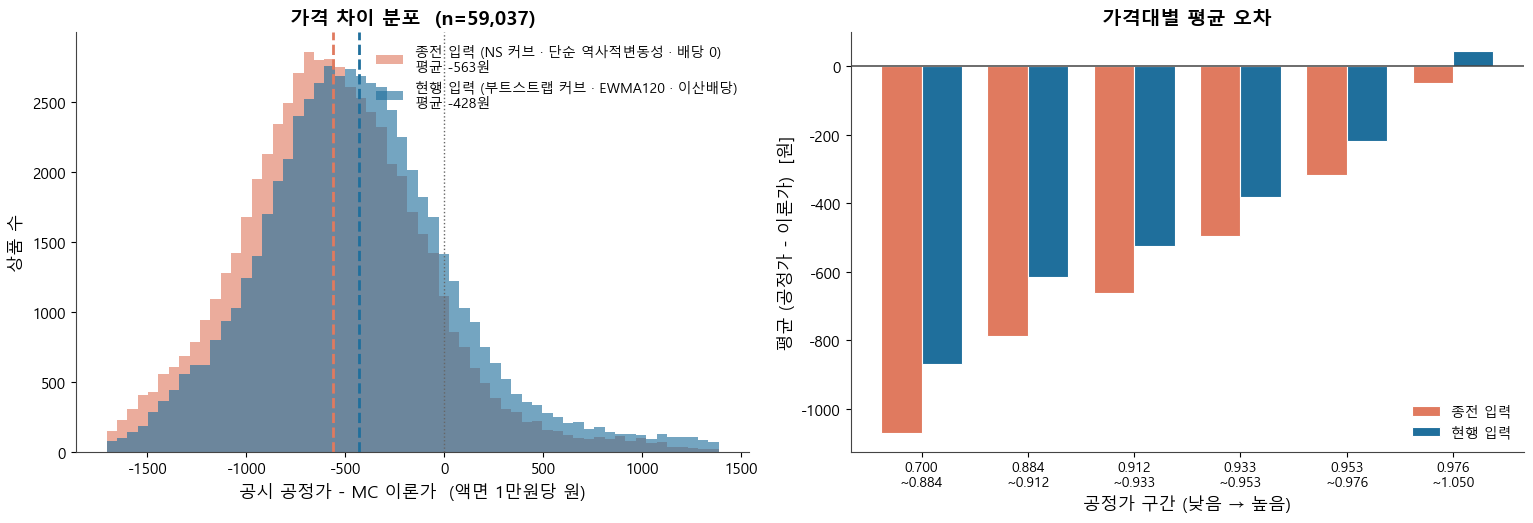

저장 result/image/fig_01_price_difference.png  + .csv


In [5]:
def fig_01_price_difference() -> None:
    """공정가 − MC 이론가: 분포와 가격구간별 오차 (입력 교체 전후)."""
    V = pd.read_parquet(fm.CACHE / "mcvar" / "mc_variants.parquet").set_index("item")
    S = pd.read_parquet(fm.DATA / "els3_dataset.parquet")[["item", "fair"]]
    S = S.join(V[["mc_A", "mc_B"]], on="item")
    S = S[np.isfinite(S.mc_A) & np.isfinite(S.mc_B)].reset_index(drop=True)
    S["e_bef"] = (S.fair - S.mc_A) * FACE
    S["e_aft"] = (S.fair - S.mc_B) * FACE
    LB, LA = "종전 입력 (NS 커브 · 단순 역사적변동성 · 배당 0)", "현행 입력 (부트스트랩 커브 · EWMA120 · 이산배당)"

    fig, ax = plt.subplots(1, 2, figsize=(15.5, 5.4))
    lo, hi = np.percentile(np.r_[S.e_bef, S.e_aft], [0.5, 99.5])
    bins = np.linspace(lo, hi, 60)
    for col, lab, col_c in (("e_bef", LB, C["before"]), ("e_aft", LA, C["after"])):
        ax[0].hist(S[col], bins=bins, color=col_c, alpha=0.62,
                   label="{}\n평균 {:+,.0f}원".format(lab, S[col].mean()))
        ax[0].axvline(S[col].mean(), color=col_c, lw=2.0, ls="--")
    ax[0].axvline(0, color="#666666", lw=1.0, ls=":")
    ax[0].set_xlabel("공시 공정가 - MC 이론가  (액면 1만원당 원)")
    ax[0].set_ylabel("상품 수")
    ax[0].set_title("가격 차이 분포  (n={:,})".format(len(S)), fontweight="bold")
    ax[0].legend(frameon=False, fontsize=10)

    q = np.unique(np.quantile(S.fair, np.linspace(0, 1, 7)))
    b = np.clip(np.digitize(S.fair, q[1:-1]), 0, len(q) - 2)
    labs = ["{:.3f}\n~{:.3f}".format(q[j], q[j + 1]) for j in range(len(q) - 1)]
    xp, w = np.arange(len(labs)), 0.38
    rows = []
    for j, (col, lab, col_c) in enumerate((("e_bef", LB, C["before"]),
                                           ("e_aft", LA, C["after"]))):
        v = [S[col][b == k].mean() for k in range(len(labs))]
        ax[1].bar(xp + (j - 0.5) * w, v, w, color=col_c, edgecolor="white", lw=0.8,
                  label=lab.split(" (")[0])
        for k in range(len(labs)):
            rows.append({"구간": labs[k].replace("\n", ""), "입력": lab, "n": int((b == k).sum()),
                         "평균 오차(원)": v[k],
                         "MAPE(%)": float((S[col][b == k].abs()
                                           / (S.fair[b == k] * FACE)).mean() * 100)})
    ax[1].axhline(0, color="#444444", lw=1.1)
    ax[1].set_xticks(xp)
    ax[1].set_xticklabels(labs, fontsize=10)
    ax[1].set_xlabel("공정가 구간 (낮음 → 높음)")
    ax[1].set_ylabel("평균 (공정가 - 이론가)  [원]")
    ax[1].set_title("가격대별 평균 오차", fontweight="bold")
    ax[1].legend(frameon=False, fontsize=10, loc="lower right")
    fig.tight_layout()
    save(fig, "fig_01_price_difference", pd.DataFrame(rows))


fig_01_price_difference()

## 7쪽 — 현행 모델 구조 (DeepONet)

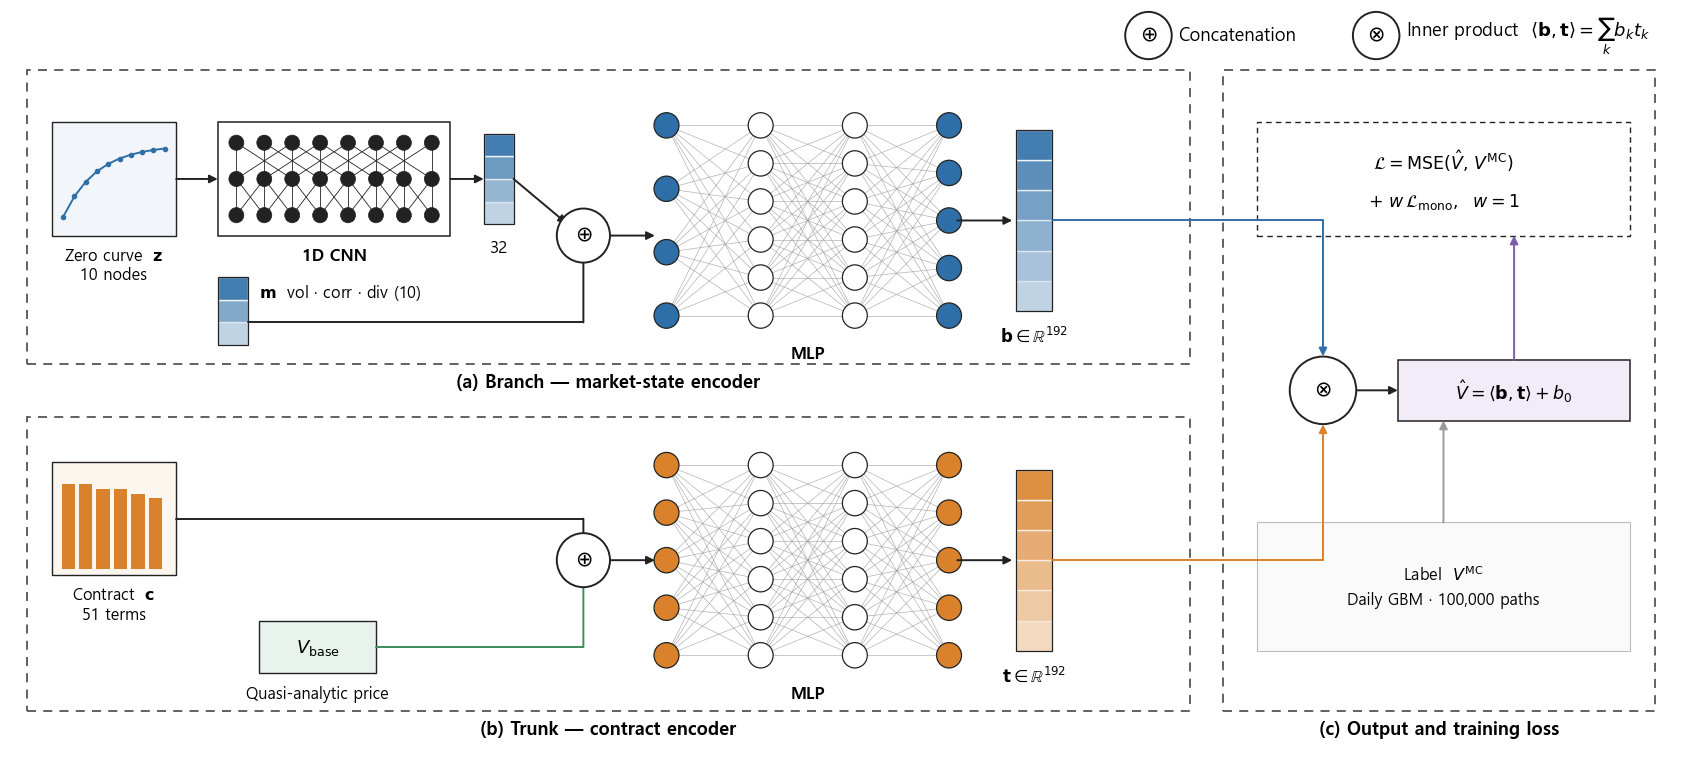

저장 result/image/fig_02_architecture.png  + .csv


In [6]:
W, H = 17.0, 7.6


AR = W / H


INK, GREY = "#222222", "#9a9a9a"


BL, OR, GR, PU = "#2f6fa7", "#d9822b", "#3a8f5c", "#7b5ea7"


def node(ax, x, y, r, fc="white", ec=INK, lw=1.1, z=4):
    """원 (가로세로 비율 보정)."""
    ax.add_patch(mp.Ellipse((x, y), 2 * r, 2 * r * AR, fc=fc, ec=ec, lw=lw, zorder=z))


def arrow(ax, x1, y1, x2, y2, col=INK, lw=1.4):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", color=col, lw=lw, shrinkA=0, shrinkB=0), zorder=6)


def line(ax, xs, ys, col=INK, lw=1.4):
    ax.plot(xs, ys, color=col, lw=lw, zorder=5, solid_capstyle="round")


def op(ax, x, y, sym, r=0.016):
    node(ax, x, y, r, lw=1.4, z=7)
    ax.text(x, y, sym, ha="center", va="center", fontsize=15, zorder=8)


def panel(ax, x, y, w, h, title):
    ax.add_patch(mp.Rectangle((x, y), w, h, fc="none", ec="#555555", lw=1.3, ls=(0, (5, 4))))
    ax.text(x + w / 2, y - 0.012, title, ha="center", va="top", fontsize=13, fontweight="bold",
            bbox=dict(fc="white", ec="none", pad=1.5))


def mlp(ax, x0, y0, w, h, layers, col):
    """뉴런과 연결선으로 그린 MLP. 첫·마지막 층은 색, 은닉층은 흰색."""
    xs = np.linspace(x0, x0 + w, len(layers))
    pos = []
    for i, n in enumerate(layers):
        ys = np.linspace(y0 + h * 0.08, y0 + h * 0.92, n) if n > 1 else [y0 + h / 2]
        pos.append([(xs[i], y) for y in ys])
    for a, b in zip(pos[:-1], pos[1:]):
        for (x1, y1) in a:
            for (x2, y2) in b:
                ax.plot([x1, x2], [y1, y2], color=GREY, lw=0.5, alpha=0.75, zorder=2)
    for i, layer in enumerate(pos):
        for (x, y) in layer:
            node(ax, x, y, 0.0075, fc=col if i in (0, len(pos) - 1) else "white", ec=INK, lw=0.9)


def vec(ax, x, y, w, h, n, col, label, below=True):
    """세로 벡터 — 칸 n 개, 위로 갈수록 진하게."""
    for i in range(n):
        ax.add_patch(mp.Rectangle((x, y + i * h / n), w, h / n, fc=col, ec="white", lw=1.0,
                                  alpha=0.30 + 0.6 * i / max(n - 1, 1), zorder=4))
    ax.add_patch(mp.Rectangle((x, y), w, h, fc="none", ec=INK, lw=0.9, zorder=5))
    if label:
        ax.text(x + w / 2, y - 0.02 if below else y + h + 0.02, label, ha="center",
                va="top" if below else "bottom", fontsize=12)


def conv(ax, x0, y0, w, h, n=8):
    """1D 합성곱 격자 — 두 층, 커널 3, 팽창 1·2."""
    ax.add_patch(mp.Rectangle((x0, y0), w, h, fc="white", ec=INK, lw=1.1, zorder=1))
    xs = np.linspace(x0 + w * 0.08, x0 + w * 0.92, n)
    rows = [y0 + h * 0.18, y0 + h * 0.5, y0 + h * 0.82]
    for r, d in ((0, 1), (1, 2)):
        for j in range(n):
            for k in (-d, 0, d):
                if 0 <= j + k < n:
                    ax.plot([xs[j + k], xs[j]], [rows[r], rows[r + 1]], color=INK, lw=0.6, zorder=2)
    for yy in rows:
        for xx in xs:
            node(ax, xx, yy, 0.0045, fc=INK, ec=INK, lw=0.5)


def fig_02_architecture() -> None:
    fig, ax = plt.subplots(figsize=(W, H))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    # 범례
    op(ax, 0.685, 0.965, r"$\oplus$", 0.014)
    ax.text(0.703, 0.965, "Concatenation", va="center", fontsize=13)
    op(ax, 0.822, 0.965, r"$\otimes$", 0.014)
    ax.text(0.840, 0.965, r"Inner product  $\langle\mathbf{b},\mathbf{t}\rangle=\sum_k b_k t_k$",
            va="center", fontsize=13)

    # ---------------- (a) Branch
    panel(ax, 0.01, 0.53, 0.70, 0.39, "(a) Branch — market-state encoder")
    ax.add_patch(mp.Rectangle((0.025, 0.70), 0.075, 0.15, fc="#f2f6fb", ec=INK, lw=1.0))
    tt = np.linspace(0, 1, 10)
    ax.plot(0.032 + 0.061 * tt, 0.725 + 0.095 * (1 - np.exp(-3 * tt)), "-o", color=BL, ms=3, lw=1.4)
    ax.text(0.0625, 0.685, "Zero curve  $\\mathbf{z}$\n10 nodes", ha="center", va="top", fontsize=11.5)
    conv(ax, 0.125, 0.70, 0.14, 0.15)
    ax.text(0.195, 0.685, "1D CNN", ha="center", va="top", fontsize=12, fontweight="bold")
    arrow(ax, 0.100, 0.775, 0.125, 0.775)
    vec(ax, 0.285, 0.715, 0.018, 0.12, 4, BL, "32")
    arrow(ax, 0.265, 0.775, 0.285, 0.775)
    vec(ax, 0.125, 0.555, 0.018, 0.09, 3, BL, None)
    ax.text(0.150, 0.625, "$\\mathbf{m}$  vol · corr · div (10)", va="center", fontsize=11.5)
    op(ax, 0.345, 0.70, r"$\oplus$")
    arrow(ax, 0.303, 0.775, 0.335, 0.716)
    line(ax, [0.143, 0.345], [0.585, 0.585])
    arrow(ax, 0.345, 0.585, 0.345, 0.682)
    mlp(ax, 0.395, 0.57, 0.17, 0.30, [4, 6, 6, 5], BL)
    ax.text(0.48, 0.555, "MLP", ha="center", va="top", fontsize=12, fontweight="bold")
    arrow(ax, 0.361, 0.70, 0.388, 0.70)
    vec(ax, 0.605, 0.60, 0.022, 0.24, 6, BL, "$\\mathbf{b}\\in\\mathbb{R}^{192}$")
    arrow(ax, 0.570, 0.72, 0.603, 0.72)

    # ---------------- (b) Trunk
    panel(ax, 0.01, 0.07, 0.70, 0.39, "(b) Trunk — contract encoder")
    ax.add_patch(mp.Rectangle((0.025, 0.25), 0.075, 0.15, fc="#fdf6ee", ec=INK, lw=1.0))
    for i, hh in enumerate([0.9, 0.9, 0.85, 0.85, 0.8, 0.75]):
        ax.add_patch(mp.Rectangle((0.031 + i * 0.0105, 0.258), 0.008, 0.125 * hh, fc=OR, ec="none"))
    ax.text(0.0625, 0.235, "Contract  $\\mathbf{c}$\n51 terms", ha="center", va="top", fontsize=11.5)
    ax.add_patch(mp.Rectangle((0.15, 0.12), 0.07, 0.07, fc="#e7f3ec", ec=INK, lw=1.0))
    ax.text(0.185, 0.155, "$V_{\\mathrm{base}}$", ha="center", va="center", fontsize=13)
    ax.text(0.185, 0.105, "Quasi-analytic price", ha="center", va="top", fontsize=11.5)
    op(ax, 0.345, 0.27, r"$\oplus$")
    line(ax, [0.100, 0.345], [0.325, 0.325])
    arrow(ax, 0.345, 0.325, 0.345, 0.288)
    line(ax, [0.220, 0.345], [0.155, 0.155], GR)
    arrow(ax, 0.345, 0.155, 0.345, 0.252, GR)
    mlp(ax, 0.395, 0.12, 0.17, 0.30, [5, 6, 6, 5], OR)
    ax.text(0.48, 0.105, "MLP", ha="center", va="top", fontsize=12, fontweight="bold")
    arrow(ax, 0.361, 0.27, 0.388, 0.27)
    vec(ax, 0.605, 0.15, 0.022, 0.24, 6, OR, "$\\mathbf{t}\\in\\mathbb{R}^{192}$")
    arrow(ax, 0.570, 0.27, 0.603, 0.27)

    # ---------------- (c) 결합과 손실
    panel(ax, 0.73, 0.07, 0.26, 0.85, "(c) Output and training loss")
    op(ax, 0.79, 0.495, r"$\otimes$", 0.02)
    line(ax, [0.627, 0.79], [0.72, 0.72], BL)
    arrow(ax, 0.79, 0.72, 0.79, 0.540, BL)
    line(ax, [0.627, 0.79], [0.27, 0.27], OR)
    arrow(ax, 0.79, 0.27, 0.79, 0.450, OR)
    ax.add_patch(mp.Rectangle((0.835, 0.455), 0.14, 0.08, fc="#f1ecf8", ec=INK, lw=1.1))
    ax.text(0.905, 0.495, "$\\hat V = \\langle\\mathbf{b},\\mathbf{t}\\rangle + b_0$", ha="center",
            va="center", fontsize=12.5)
    arrow(ax, 0.810, 0.495, 0.835, 0.495)
    ax.add_patch(mp.Rectangle((0.75, 0.70), 0.225, 0.15, fc="white", ec=INK, lw=1.0, ls=(0, (4, 3))))
    ax.text(0.8625, 0.80, "$\\mathcal{L} = \\mathrm{MSE}(\\hat V,\\,V^{\\mathrm{MC}})$", ha="center",
            va="center", fontsize=12.5)
    ax.text(0.8625, 0.745, "$+\\ w\\,\\mathcal{L}_{\\mathrm{mono}},\\ \\ w=1$", ha="center", va="center",
            fontsize=12.5)
    arrow(ax, 0.905, 0.535, 0.905, 0.70, PU)
    ax.add_patch(mp.Rectangle((0.75, 0.15), 0.225, 0.17, fc="#fafafa", ec="#bbbbbb", lw=0.8))
    ax.text(0.8625, 0.235, "Label  $V^{\\mathrm{MC}}$\nDaily GBM · 100,000 paths", ha="center", va="center",
            fontsize=11.5, linespacing=1.5)
    arrow(ax, 0.8625, 0.32, 0.8625, 0.455, GREY)
    fig.tight_layout(pad=0.15)
    T = pd.DataFrame([
        {"구성요소": "Branch 입력", "형태": "z 10 → 1D CNN 32, m 10", "설명": "제로커브 합성곱 요약 후 m 과 이어붙임"},
        {"구성요소": "Branch MLP", "형태": "42 → 192", "설명": "b"},
        {"구성요소": "Trunk 입력", "형태": "c 51, V_base 1", "설명": "이어붙임"},
        {"구성요소": "Trunk MLP", "형태": "52 → 192", "설명": "t"},
        {"구성요소": "출력", "형태": "1", "설명": "<b, t> + b0"},
        {"구성요소": "손실", "형태": "-", "설명": "MSE + w·L_mono, w = 1"},
    ])
    save(fig, "fig_02_architecture", T)


fig_02_architecture()

## 12쪽 — V_base 절제 실험 (피처 실험)

단조손실 없이 계약 블록에 덧붙인 피처만 바꾼 네 변형. 시드 5개 지표 평균 ± 표준오차.

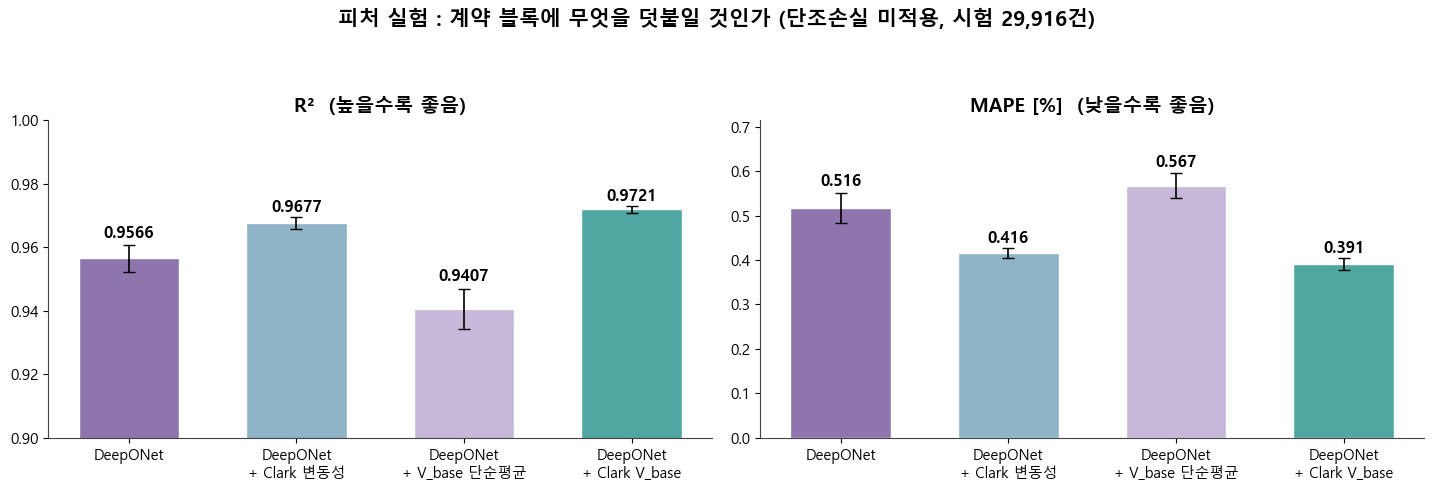

저장 result/image/fig_04_feature_experiment.png  + .csv


In [7]:
def fig_04_feature_experiment() -> None:
    """피처 실험 — 단조손실 없는 네 변형. 시드별 지표의 평균 ± 표준오차."""
    B = bundle()
    oos, mc = B["oos"], B["mc"]
    src = [("DeepONet", fm.CACHE / "nb_pred_abl_neither.npy"),
           ("DeepONet + Clark 변동성", fm.CACHE / "nb_pred_abl_vsc.npy"),
           ("DeepONet + V_base 단순평균", fm.CACHE / "nb_pred_abl_vmean.npy"),
           ("DeepONet + Clark V_base", fm.CACHE / "nb_pred_abl_vb.npy")]
    rows = []
    for lab, p in src:
        pr = np.load(p)
        if pr.shape != (5, len(oos)):
            raise RuntimeError("{} 모양 {}".format(p.name, pr.shape))
        per = [metrics(pr[s], mc[oos]) for s in range(5)]
        r = {"피처 구성": lab, "n": len(oos)}
        for key in ("R2", "MAPE", "RMSE", "MAE"):
            r[key] = float(np.mean([q[key] for q in per]))
            r[key + "_se"] = float(np.std([q[key] for q in per], ddof=1) / np.sqrt(5))
        rows.append(r)
    T = pd.DataFrame(rows)

    fig, ax = plt.subplots(1, 2, figsize=(14.5, 5.0))
    x = np.arange(len(T))
    cols = [C["DeepONet"], "#8fb3c7", "#c7b7d9", C["DeepONet + f"]]
    xt = ["DeepONet", "DeepONet\n+ Clark 변동성", "DeepONet\n+ V_base 단순평균", "DeepONet\n+ Clark V_base"]
    for a, key, ttl, fmt in ((ax[0], "R2", "R²  (높을수록 좋음)", "{:.4f}"),
                             (ax[1], "MAPE", "MAPE [%]  (낮을수록 좋음)", "{:.3f}")):
        a.bar(x, T[key], 0.6, yerr=T[key + "_se"], color=cols, edgecolor="white",
              capsize=4, error_kw={"lw": 1.2})
        for xx, v, se in zip(x, T[key], T[key + "_se"]):
            a.text(xx, v + se * 1.2, fmt.format(v), ha="center", va="bottom", fontsize=11.5,
                   fontweight="bold")
        a.set_xticks(x)
        a.set_xticklabels(xt, fontsize=10.5)
        a.set_title(ttl, fontweight="bold")
        a.margins(y=0.2)
    ax[0].set_ylim(0.90, 1.0)
    fig.suptitle("피처 실험 : 계약 블록에 무엇을 덧붙일 것인가 (단조손실 미적용, 시험 {:,}건)".format(len(oos)),
                 fontsize=15, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.92])
    save(fig, "fig_04_feature_experiment", T)


fig_04_feature_experiment()

## 14쪽 — 단조손실 효과: 리자드 지급률 배수에 대한 가격 반응

시험 리자드 상품 전수에서 지급률만 0.5~1.5배로 바꿨을 때의 평균 가격(위)과 상품별 기울기(아래). MC 는 준비 2 의 조건 변경 MC 를 씁니다.

    fold 0 : 리자드 940건


    fold 1 : 리자드 450건


    fold 2 : 리자드 414건


    fold 3 : 리자드 954건


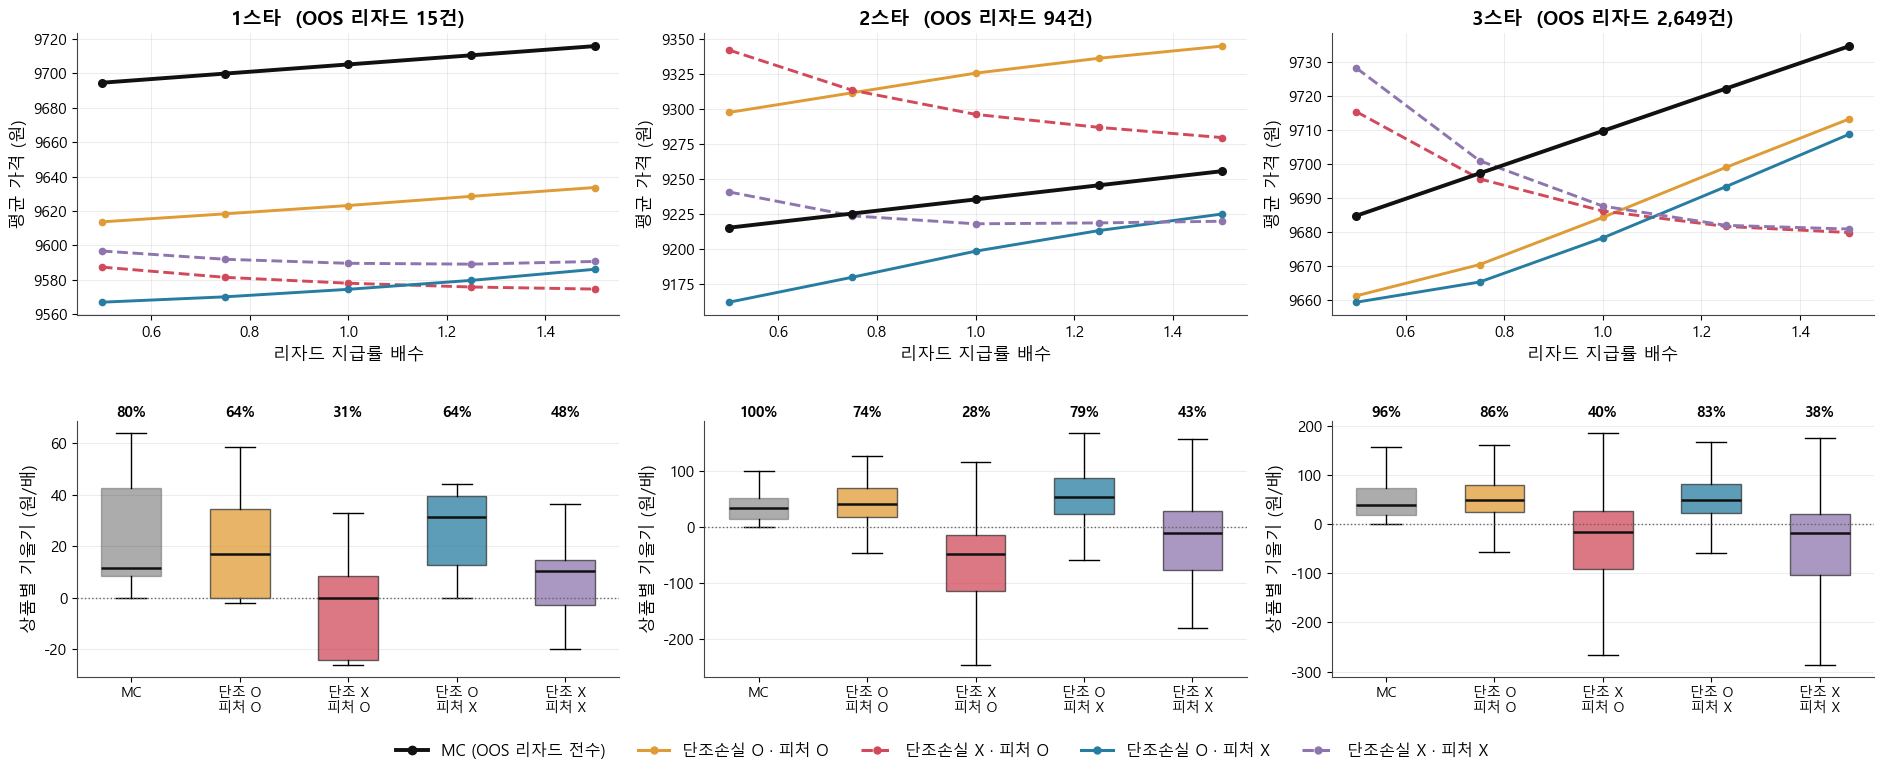

저장 result/image/fig_03_mono_effect.png  + .csv


In [8]:
LEVELS = [0.5, 0.75, 1.0, 1.25, 1.5]
MONO4 = [("단조손실 O · 피처 O", "canon", "ball_dm", True, C["DeepONet + f + m"]),
         ("단조손실 X · 피처 O", "canon", "abl_vb", True, "#d1495b"),
         ("단조손실 O · 피처 X", "canon", "ball_d", False, C["DeepONet + m"]),
         ("단조손실 X · 피처 X", "canon", "abl_neither", False, C["DeepONet"])]


def _lizard_grid_all_oos():
    """OOS 리자드 상품 전수에서 지급률 배수 0.5~1.5 에 대한 네 모형의 가격.

    출력
      P   : dict 모형 → ndarray(5 시드, 5 수준, n 리자드) [원]
      liz : ndarray — 리자드 상품 인덱스 (전체 길이 기준)
    """
    B = bundle()
    D, fold, oos, nstar, has_lz = B["D"], B["fold"], B["oos"], B["nstar"], B["has_lz"]
    liz = oos[has_lz[oos]]
    P = {m[0]: np.full((5, len(LEVELS), len(liz)), np.nan) for m in MONO4}
    nobs = np.asarray(D.nobs)
    for k in range(len(D.WF)):
        sel = np.where(fold[liz] == k)[0]
        if not len(sel):
            continue
        idx = liz[sel]
        for j, lev in enumerate(LEVELS):
            X = CS.scale_lizard_pmt(D.CON[idx], lev, has_lz[idx])
            vb = vbase_els(X, D.VC[idx], D.CURVE[idx], nobs[idx], mode="clark",
                           nstar=nstar[idx])
            Xf = np.concatenate([X, np.nan_to_num(vb, nan=0.0).astype("float32")[:, None]],
                                1).astype("float32")
            for lab, wd, pre, ft, _ in MONO4:
                for s in range(5):
                    P[lab][s, j, sel] = _don(wd, pre, s, k)(D.CURVE[idx], D.VC[idx],
                                                            Xf if ft else X) * FACE
        print("    fold {} : 리자드 {}건".format(k, len(idx)), flush=True)
    return P, liz


def fig_03_mono_effect() -> None:
    """위: 지급률 배수별 평균 가격 곡선.  아래: 상품별 기울기 상자그림.

    MC 는 준비 2 의 조건 변경 MC (같은 OOS 리자드 전수, 같은 배수)다.
    """
    B = bundle()
    D, nstar = B["D"], B["nstar"]
    P, liz = _lizard_grid_all_oos()
    R = PERT[PERT["factor"] == "lz_pmt_scale"]
    piv = R.pivot_table(index="item", columns="level", values="mc")
    items = [D.ITEM[i] for i in liz]
    if piv.reindex(items).isna().any().any():
        raise RuntimeError("조건 변경 MC 가 비어 있는 리자드 상품이 있다 — 준비 2 를 확인할 것")
    MCg = piv.reindex(items)[LEVELS].to_numpy().T          # 수준 × 상품
    span = LEVELS[-1] - LEVELS[0]
    xs = np.array(LEVELS)
    stars = [s for s in (1, 2, 3) if (nstar[liz] == s).any()]
    fig, axes = plt.subplots(2, len(stars), figsize=(19.0, 7.8), gridspec_kw={"height_ratios": [1.1, 1.0]})
    rows, curves = [], []
    for c, ns in enumerate(stars):
        m = nstar[liz] == ns
        ax, bx = axes[0, c], axes[1, c]
        mc_cur = MCg[:, m]
        mc_slope = (mc_cur[-1] - mc_cur[0]) / span
        ax.plot(xs, mc_cur.mean(1), "-o", color=C["MC"], lw=2.8, ms=5.5, zorder=6)
        curves += [{"스타": ns, "모형": "MC", "배수": lv, "평균 가격(원)": float(v)}
                   for lv, v in zip(LEVELS, mc_cur.mean(1))]
        rows.append({"스타": ns, "모형": "MC", "상품 수": int(m.sum()),
                     "부호 옳은 비율(%)": float((mc_slope > 0).mean() * 100),
                     "중위 기울기(원/배)": float(np.median(mc_slope)),
                     "평균 기울기(원/배)": float(mc_slope.mean())})
        data, cols = [mc_slope], [C["MC"]]
        for lab, _, _, _, col in MONO4:
            cur = P[lab][:, :, m]
            slope = (cur[:, -1] - cur[:, 0]) / span
            v = cur.mean(axis=(0, 2))
            ax.plot(xs, v, "-" if lab.startswith("단조손실 O") else "--", marker="o", color=col, lw=2.1, ms=4.5)
            curves += [{"스타": ns, "모형": lab, "배수": lv, "평균 가격(원)": float(x)} for lv, x in zip(LEVELS, v)]
            data.append(slope.mean(0))
            cols.append(col)
            rows.append({"스타": ns, "모형": lab, "상품 수": int(m.sum()),
                         "부호 옳은 비율(%)": float((slope > 0).mean() * 100),
                         "중위 기울기(원/배)": float(np.median(slope.mean(0))),
                         "평균 기울기(원/배)": float(slope.mean())})
        ax.set_title("{}스타  (OOS 리자드 {:,}건)".format(ns, int(m.sum())), fontweight="bold")
        ax.set_xlabel("리자드 지급률 배수")
        ax.set_ylabel("평균 가격 (원)")
        ax.grid(alpha=0.22)
        bp = bx.boxplot(data, widths=0.55, showfliers=False, patch_artist=True,
                        medianprops=dict(color="#111111", lw=1.8))
        for patch, col in zip(bp["boxes"], cols):
            patch.set(facecolor=col, alpha=0.75 if col != C["MC"] else 0.35, edgecolor="#333333")
        bx.axhline(0, color="#666666", lw=1.0, ls=":")
        for i, r in enumerate(rows[-5:]):
            bx.text(i + 1, 1.0, "{:.0f}%".format(r["부호 옳은 비율(%)"]), transform=bx.get_xaxis_transform(),
                    ha="center", va="bottom", fontsize=10.5, fontweight="bold")
        bx.set_xticks(range(1, 6))
        bx.set_xticklabels(["MC", "단조 O\n피처 O", "단조 X\n피처 O", "단조 O\n피처 X", "단조 X\n피처 X"], fontsize=10)
        bx.set_ylabel("상품별 기울기 (원/배)")
        bx.grid(axis="y", alpha=0.22)
    handles = [Line2D([0], [0], color=C["MC"], lw=2.8, marker="o", ms=6, label="MC (OOS 리자드 전수)")]
    handles += [Line2D([0], [0], color=col, lw=2.2, ls="-" if lab.startswith("단조손실 O") else "--",
                       marker="o", ms=5, label=lab) for lab, _, _, _, col in MONO4]
    fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, fontsize=11.5)
    fig.tight_layout(rect=[0, 0.05, 1, 1], h_pad=2.5)
    pd.DataFrame(curves).to_csv(IMG / "fig_03_mono_effect_curves.csv",
                                index=False, encoding="utf-8-sig")
    save(fig, "fig_03_mono_effect", pd.DataFrame(rows))


fig_03_mono_effect()

## 15–19쪽 — 예측가격 산점도 (다섯 모형 누적)

XGBoost → DeepONet → +단조손실(m) → +V_base(f) → +f+m 순서로 한 장씩 겹칩니다.

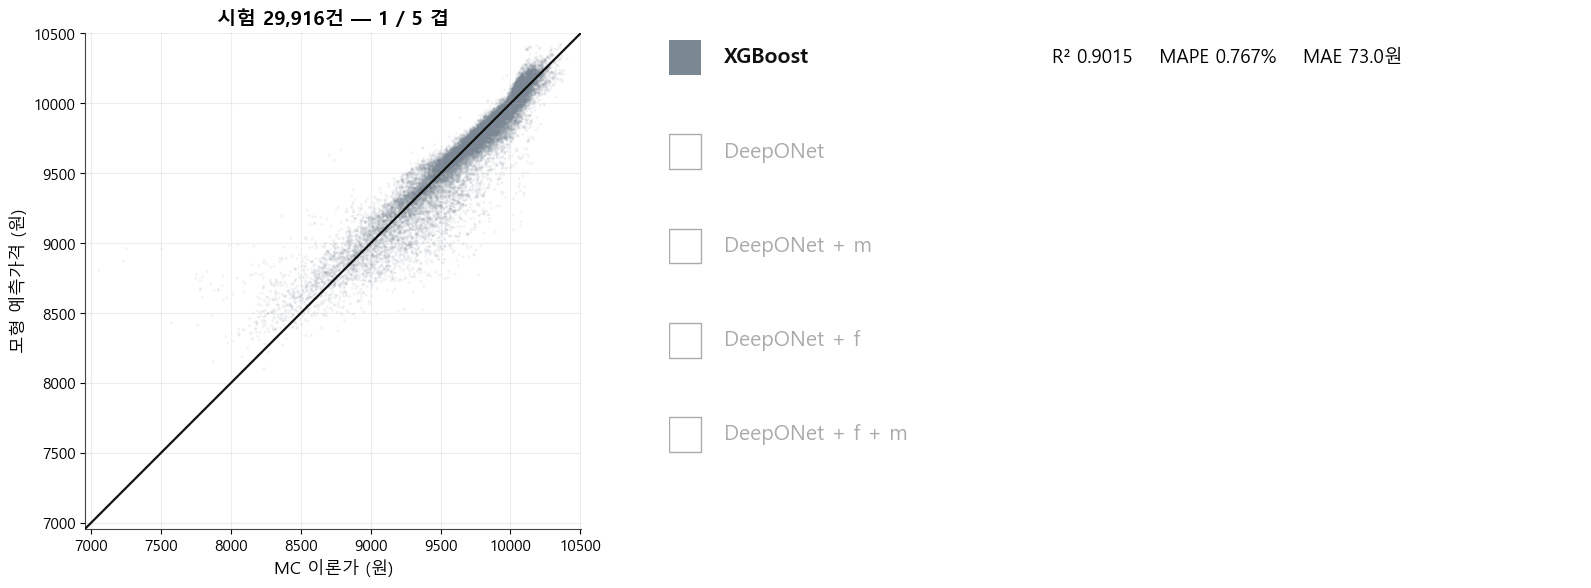

저장 result/image/fig_15_scatter_stack_1.png


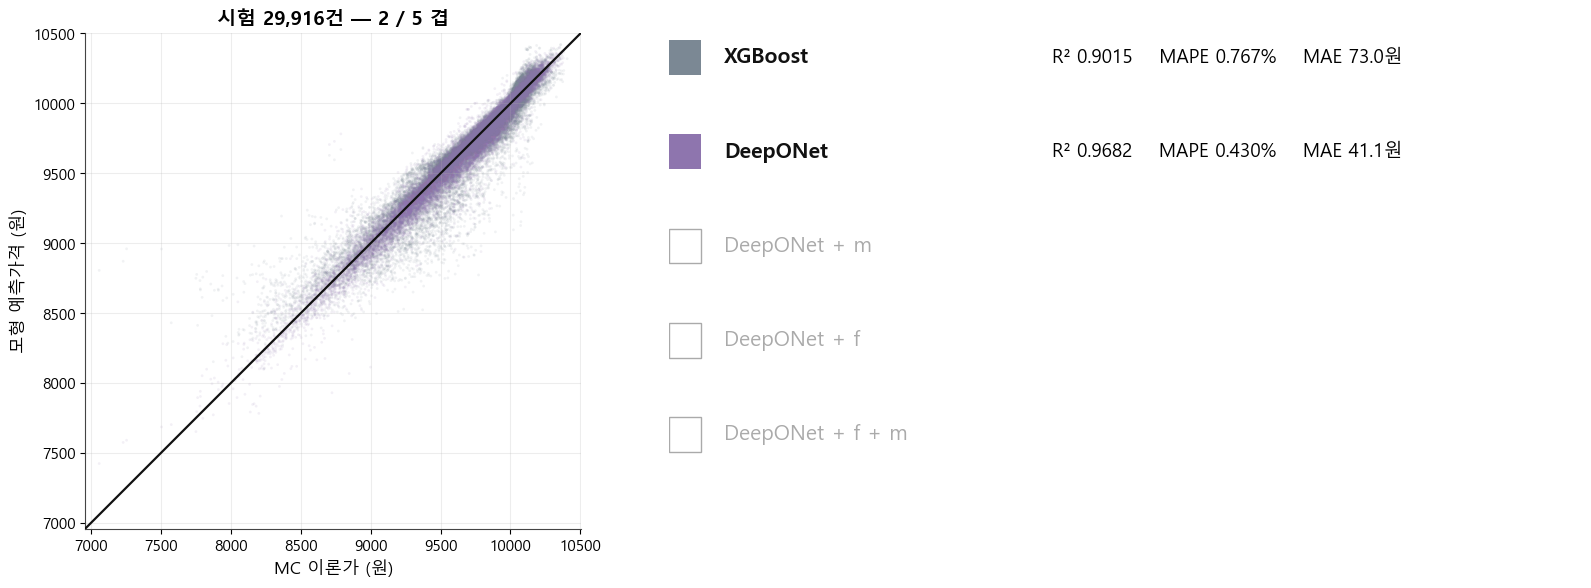

저장 result/image/fig_15_scatter_stack_2.png


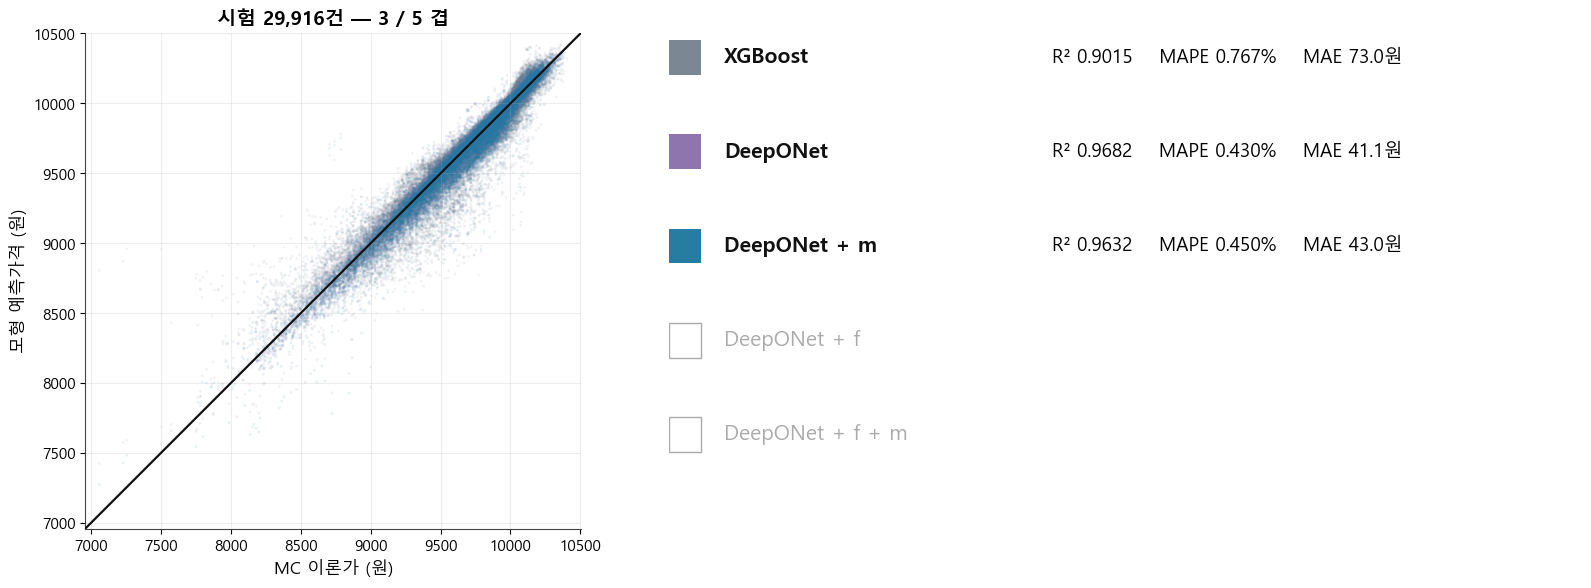

저장 result/image/fig_15_scatter_stack_3.png


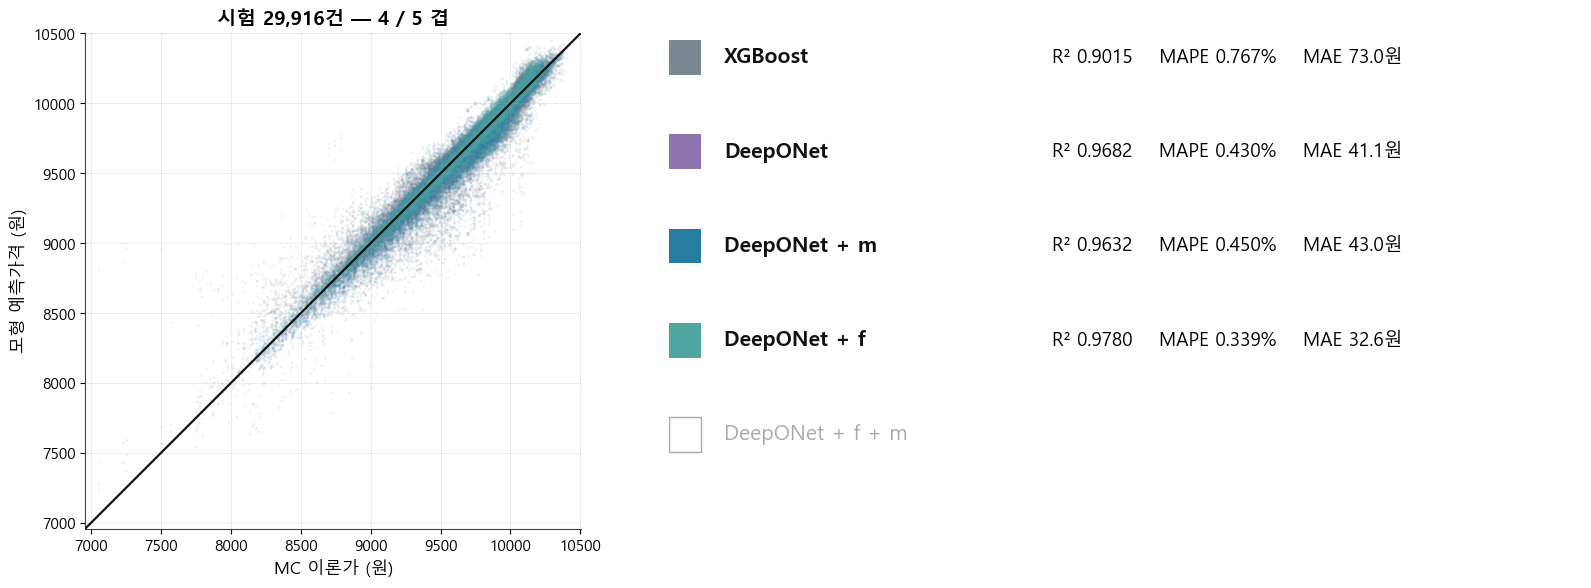

저장 result/image/fig_15_scatter_stack_4.png


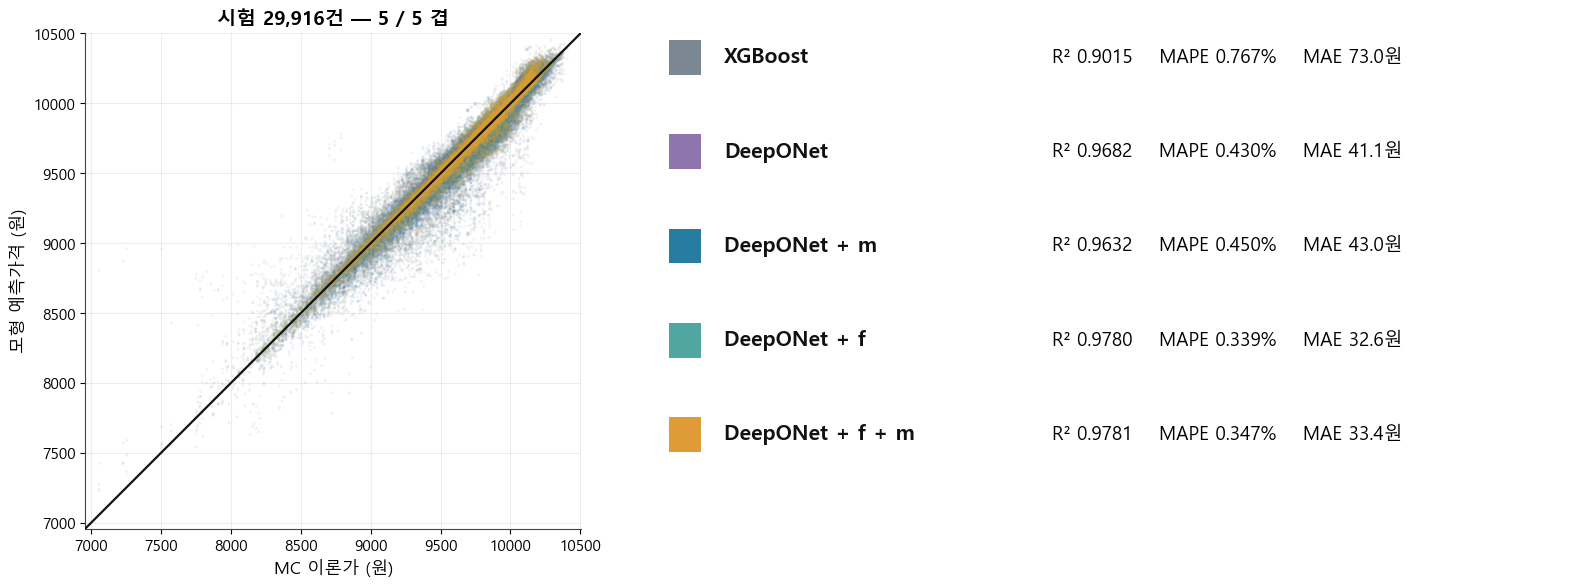

저장 result/image/fig_15_scatter_stack_5.png  + .csv


In [9]:
STACK = ["XGBoost", "DeepONet", "DeepONet + m", "DeepONet + f", "DeepONet + f + m"]


def fig_15_scatter_stack() -> None:
    import matplotlib.patches as mp
    B = bundle()
    oos, mc, P = B["oos"], B["mc"], B["P"]
    y = mc[oos]
    lo, hi = float(y.min()), float(y.max())
    pad = (hi - lo) * 0.03
    rows = []
    for k in range(1, len(STACK) + 1):
        fig = plt.figure(figsize=(16.0, 6.2))
        ax = fig.add_axes([0.055, 0.11, 0.31, 0.80])
        tx = fig.add_axes([0.42, 0.11, 0.57, 0.80])
        tx.axis("off")
        ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], "-", color=C["MC"], lw=1.6, zorder=9)
        for lab in STACK[:k]:
            ax.scatter(y, P[lab][oos], s=4, alpha=0.10, color=C[lab], edgecolors="none", rasterized=True)
        ax.set_xlim(lo - pad, hi + pad)
        ax.set_ylim(lo - pad, hi + pad)
        ax.set_xlabel("MC 이론가 (원)")
        ax.set_ylabel("모형 예측가격 (원)")
        ax.set_title("시험 {:,}건 — {} / {} 겹".format(len(y), k, len(STACK)), fontweight="bold")
        ax.grid(alpha=0.22)
        yy = 0.95
        for i, lab in enumerate(STACK):
            on = i < k
            m = metrics(P[lab][oos], y)
            tx.add_patch(mp.Rectangle((0.0, yy - 0.035), 0.035, 0.07, color=C[lab] if on else "none",
                                      ec=None if on else "#aaaaaa"))
            tx.text(0.06, yy, lab, fontsize=15, fontweight="bold" if on else "normal",
                    color="#111111" if on else "#aaaaaa", va="center")
            if on:
                tx.text(0.42, yy, "R² {:.4f}    MAPE {:.3f}%    MAE {:.1f}원".format(m["R2"], m["MAPE"], m["MAE"]),
                        fontsize=13.5, va="center")
            if k == len(STACK):
                rows.append({"모형": lab, "n": len(y), **m})
            yy -= 0.19
        save(fig, "fig_15_scatter_stack_{}".format(k), pd.DataFrame(rows) if k == len(STACK) else None)


fig_15_scatter_stack()

## 20쪽 — 모델 비교

시드 5개 지표 평균 ± 표준오차 (12쪽 표와 같은 기준).

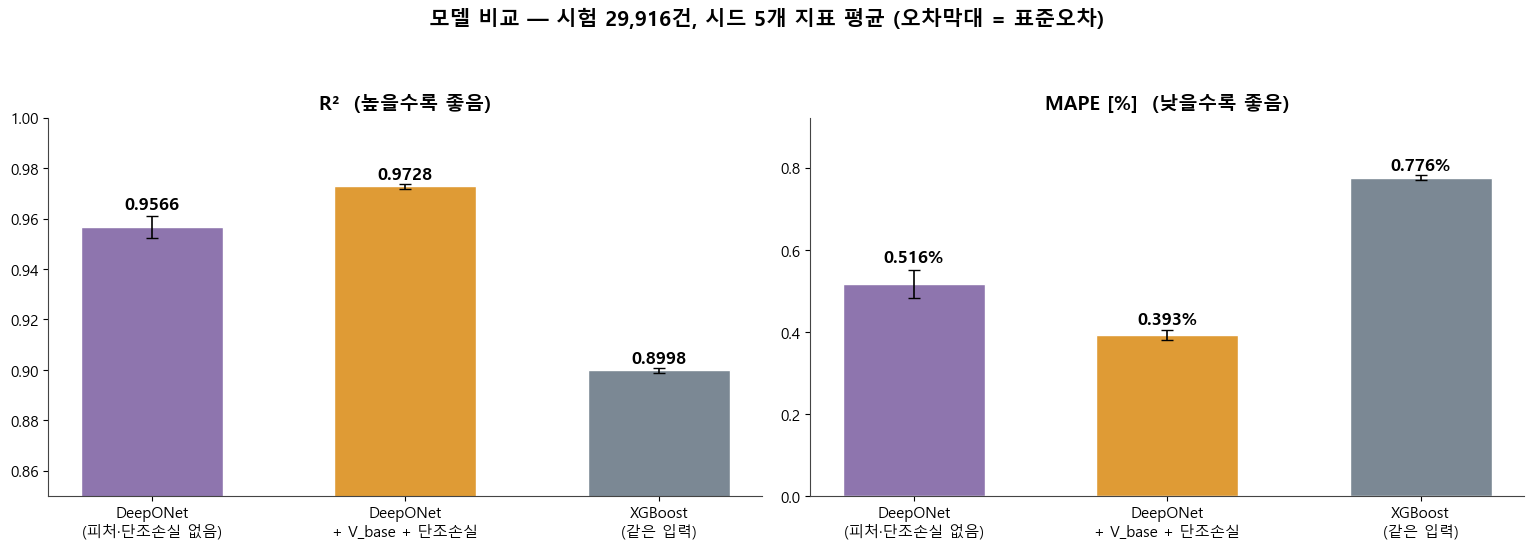

저장 result/image/fig_05_model_compare.png  + .csv


In [10]:
def _seed_preds():
    """세 모형의 시드별 OOS 예측 (5, n_oos) [원]."""
    B = bundle()
    D, oos = B["D"], B["oos"]
    dm = np.load(fm.CACHE / "nb_pred_ball_dm.npy")[:, oos]
    nei = np.load(fm.CACHE / "nb_pred_abl_neither.npy")
    x = np.full((5, D.n), np.nan)
    for s in range(5):
        for k, (_, _, te) in enumerate(D.WF):
            x[s, te] = AN.load("ball_xgb", s, k, kind="xgb")(D.CURVE[te], D.VC[te], D.CON[te]) * FACE
    return {"DeepONet": nei, MAIN: dm, "XGBoost": x[:, oos]}


def fig_05_model_compare() -> None:
    """시드별 지표의 평균 ± 표준오차 — 피처 실험(표 3)과 같은 기준."""
    B = bundle()
    oos, mc = B["oos"], B["mc"]
    P = _seed_preds()
    rows = []
    for lab in ("DeepONet", MAIN, "XGBoost"):
        per = [metrics(P[lab][s], mc[oos]) for s in range(5)]
        r = {"모형": lab, "n": len(oos)}
        for key in ("R2", "MAPE", "RMSE", "MAE", "bias"):
            v = [q[key] for q in per]
            r[key], r[key + "_se"] = float(np.mean(v)), float(np.std(v, ddof=1) / np.sqrt(5))
        rows.append(r)
    T = pd.DataFrame(rows)
    fig, ax = plt.subplots(1, 2, figsize=(15.5, 5.6))
    x = np.arange(len(T))
    cols = [C[l] for l in T["모형"]]
    labs = ["DeepONet\n(피처·단조손실 없음)", "DeepONet\n+ V_base + 단조손실", "XGBoost\n(같은 입력)"]
    for a, key, ttl, fmt in ((ax[0], "R2", "R²  (높을수록 좋음)", "{:.4f}"),
                             (ax[1], "MAPE", "MAPE [%]  (낮을수록 좋음)", "{:.3f}%")):
        a.bar(x, T[key], 0.56, yerr=T[key + "_se"], color=cols, edgecolor="white", capsize=4,
              error_kw={"lw": 1.2})
        for xx, v, e in zip(x, T[key], T[key + "_se"]):
            a.text(xx, v + e * 1.3, fmt.format(v), ha="center", va="bottom", fontsize=12.5, fontweight="bold")
        a.set_xticks(x)
        a.set_xticklabels(labs, fontsize=11)
        a.set_title(ttl, fontweight="bold")
        a.margins(y=0.18)
    ax[0].set_ylim(0.85, 1.0)
    fig.suptitle("모델 비교 — 시험 {:,}건, 시드 5개 지표 평균 (오차막대 = 표준오차)".format(len(oos)),
                 fontsize=15, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    save(fig, "fig_05_model_compare", T)


fig_05_model_compare()

## 22쪽 — 데이터셋 구성

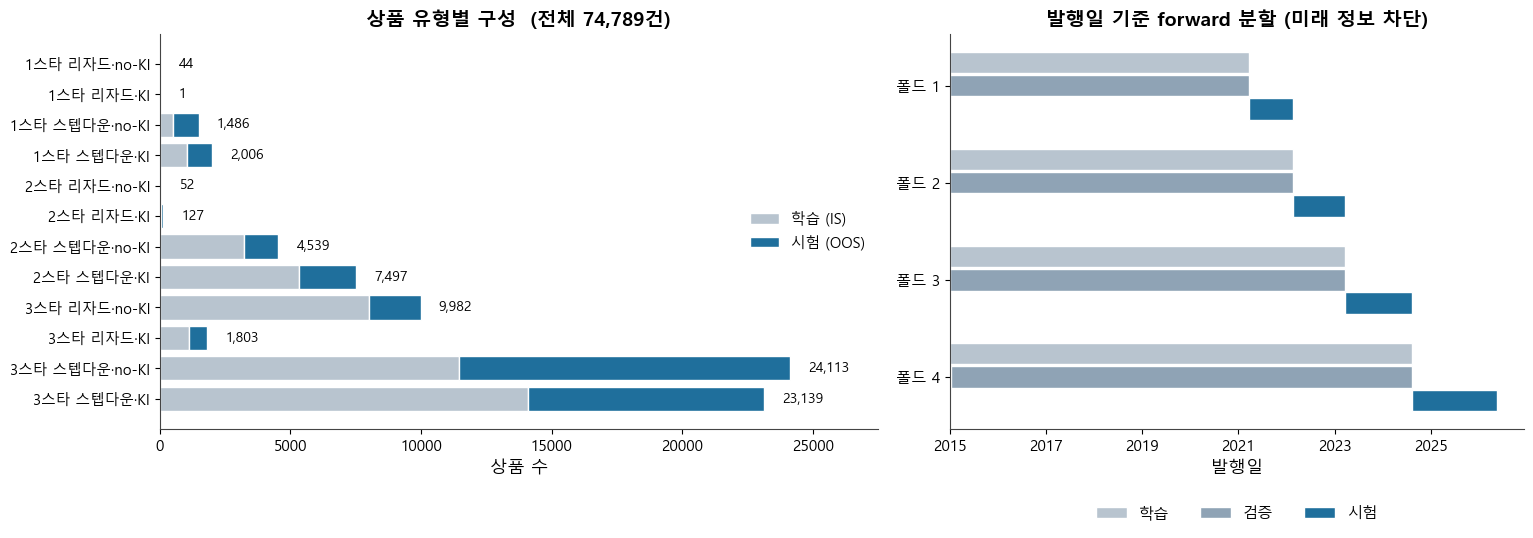

저장 result/image/fig_06_dataset_composition.png  + .csv


In [11]:
def fig_06_dataset_composition() -> None:
    """데이터셋 구성 — 스타·구조별 건수와 발행일 기준 forward 분할."""
    B = bundle()
    D, fold, nstar, has_lz, has_ki = B["D"], B["fold"], B["nstar"], B["has_lz"], B["has_ki"]
    ordv = B["ord"]
    rows = []
    for s in (1, 2, 3):
        for lz in (False, True):
            for ki in (False, True):
                m = (nstar == s) & (has_lz == lz) & (has_ki == ki)
                if not m.sum():
                    continue
                rows.append({"유형": type_label(s, lz, ki), "스타": s,
                             "구조": "리자드" if lz else "스텝다운", "KI": "있음" if ki else "없음",
                             "전체": int(m.sum()), "IS": int((m & (fold < 0)).sum()),
                             "OOS": int((m & (fold >= 0)).sum())})
    T = pd.DataFrame(rows).sort_values(["스타", "구조", "KI"]).reset_index(drop=True)

    fig, ax = plt.subplots(1, 2, figsize=(15.5, 5.6),
                           gridspec_kw={"width_ratios": [1.25, 1.0]})
    y = np.arange(len(T))[::-1]
    ax[0].barh(y, T["IS"], color="#b8c4cf", edgecolor="white", label="학습 (IS)")
    ax[0].barh(y, T["OOS"], left=T["IS"], color=C["after"], edgecolor="white", label="시험 (OOS)")
    for yy, (_, r) in zip(y, T.iterrows()):
        ax[0].text(r["전체"] + 700, yy, "{:,}".format(r["전체"]), va="center", fontsize=10)
    ax[0].set_yticks(y)
    ax[0].set_yticklabels(T["유형"], fontsize=10.5)
    ax[0].set_xlabel("상품 수")
    ax[0].set_title("상품 유형별 구성  (전체 {:,}건)".format(int(T["전체"].sum())), fontweight="bold")
    ax[0].legend(frameon=False, loc="center right", fontsize=10.5)
    ax[0].margins(x=0.14)

    for k, (tr, va, te) in enumerate(D.WF):
        # 역할마다 y 를 조금씩 띄운다 — 같은 자리에 그리면 뒤에 그린 것이 앞을 덮는다
        for dy, (nm, idx, col) in zip((-0.24, 0.0, 0.24),
                                      (("학습", tr, "#b8c4cf"), ("검증", va, "#8fa3b5"),
                                       ("시험", te, C["after"]))):
            lo, hi = date.fromordinal(int(ordv[idx].min())), date.fromordinal(int(ordv[idx].max()))
            ax[1].barh(k + dy, (hi - lo).days, left=(lo - date(2015, 1, 1)).days, height=0.22,
                       color=col, edgecolor="white", label=nm if k == 0 else None)
    ax[1].set_yticks(range(4))
    ax[1].set_yticklabels(["폴드 {}".format(i + 1) for i in range(4)])
    ticks = [date(y_, 1, 1) for y_ in range(2015, 2027, 2)]
    ax[1].set_xticks([(t - date(2015, 1, 1)).days for t in ticks])
    ax[1].set_xticklabels([t.year for t in ticks])
    ax[1].set_xlabel("발행일")
    ax[1].set_title("발행일 기준 forward 분할 (미래 정보 차단)", fontweight="bold")
    ax[1].legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.16))
    ax[1].invert_yaxis()
    fig.tight_layout()

    fr = []
    for k, (tr, va, te) in enumerate(D.WF):
        fr.append({"폴드": k + 1, "학습 n": len(tr), "검증 n": len(va), "시험 n": len(te),
                   "학습 시작": str(date.fromordinal(int(ordv[tr].min()))),
                   "학습 끝": str(date.fromordinal(int(ordv[tr].max()))),
                   "시험 시작": str(date.fromordinal(int(ordv[te].min()))),
                   "시험 끝": str(date.fromordinal(int(ordv[te].max())))})
    save(fig, "fig_06_dataset_composition",
         pd.concat([T, pd.DataFrame(fr)], axis=0, ignore_index=True))


fig_06_dataset_composition()

## 23쪽 — 기초자산 수별 성능 (R² · MAPE)

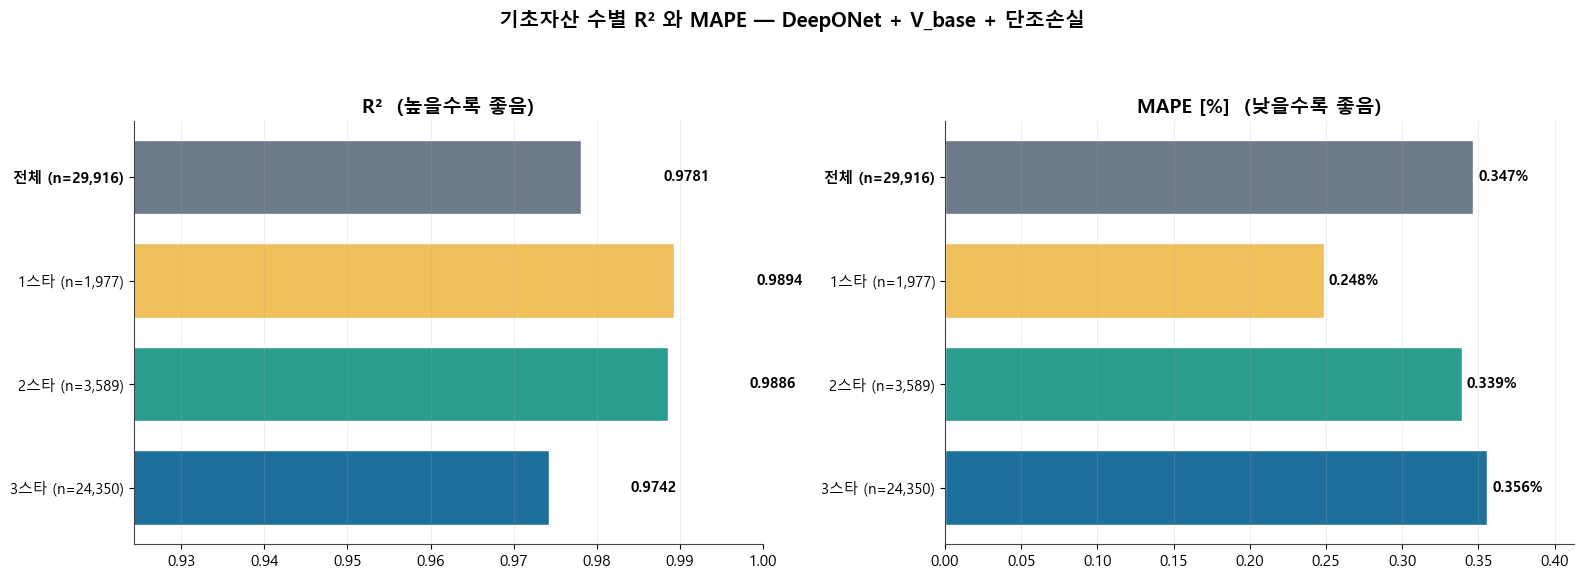

저장 result/image/fig_11_star_r2_mape.png  + .csv


In [12]:
def fig_11_star_r2_mape():
    g = [(lab, idx, C["star{}".format(k + 1)]) for k, (lab, idx, _) in enumerate(star_groups())]
    r2_mape_h(g, "fig_11_star_r2_mape", "기초자산 수별 R² 와 MAPE — DeepONet + V_base + 단조손실", tot_col="#6c7a89")


fig_11_star_r2_mape()

## 24쪽 — 기초자산 수별 절대오차 구간

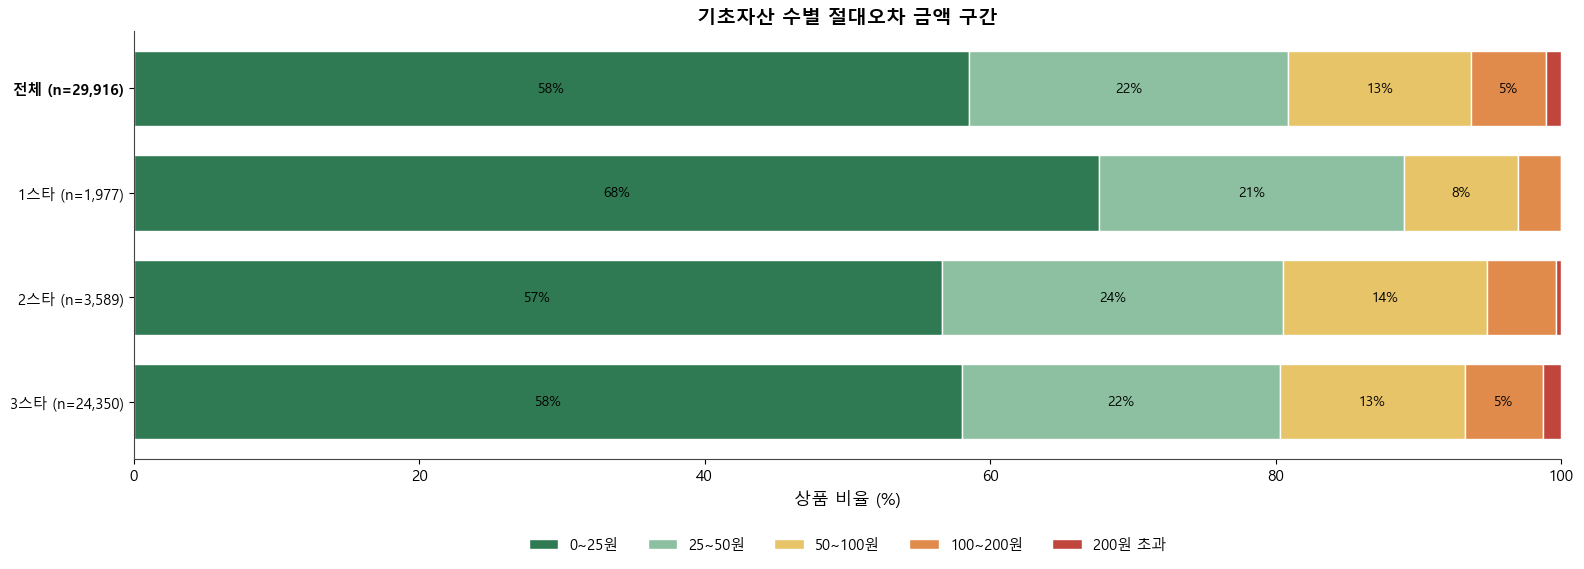

저장 result/image/fig_08_star_error.png  + .csv


In [13]:
def fig_08_star_error():
    bands_h(star_groups(), "fig_08_star_error", "기초자산 수별 절대오차 금액 구간")


fig_08_star_error()

## 25쪽 — 상품 유형별 성능 (R² · MAPE)

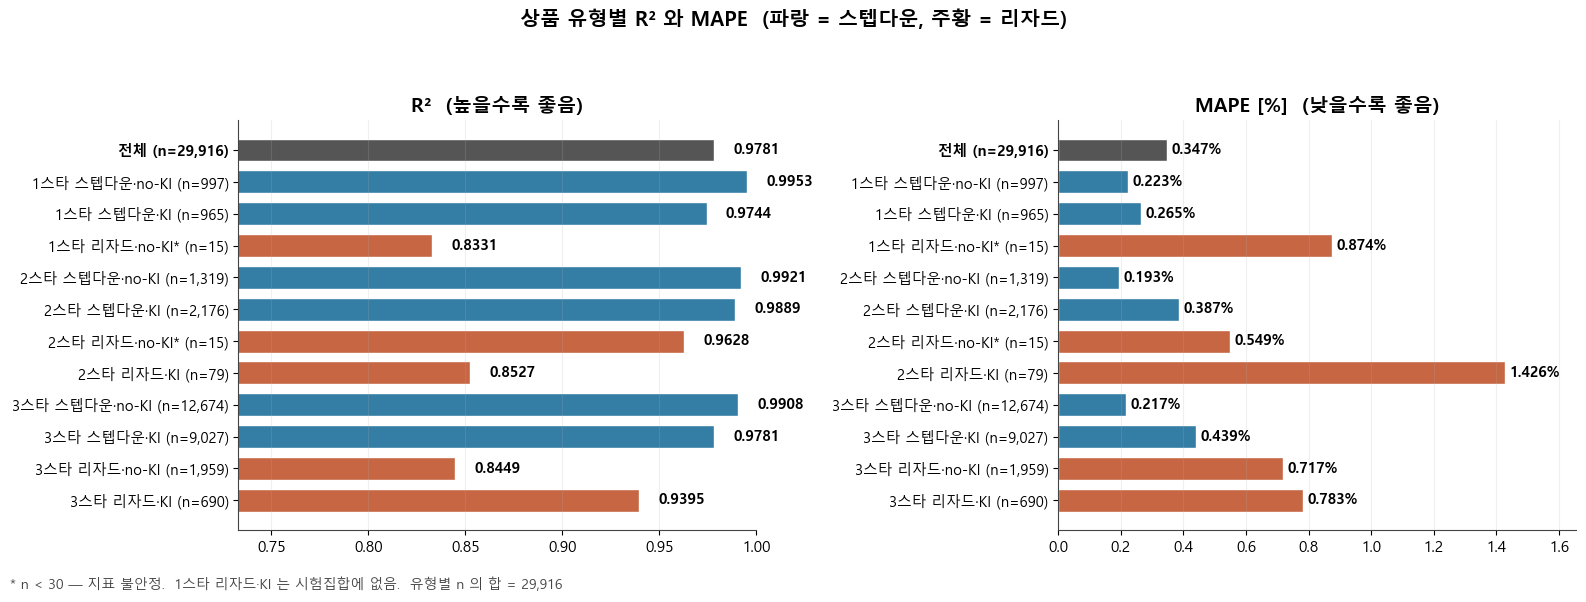

저장 result/image/fig_16_type_r2_mape.png  + .csv


In [14]:
def fig_16_type_r2_mape():
    r2_mape_h(type_groups(), "fig_16_type_r2_mape", "상품 유형별 R² 와 MAPE  (파랑 = 스텝다운, 주황 = 리자드)",
              note="* n < 30 — 지표 불안정.  1스타 리자드·KI 는 시험집합에 없음.  유형별 n 의 합 = 29,916")


fig_16_type_r2_mape()

## 26쪽 — 상품 유형별 절대오차 구간

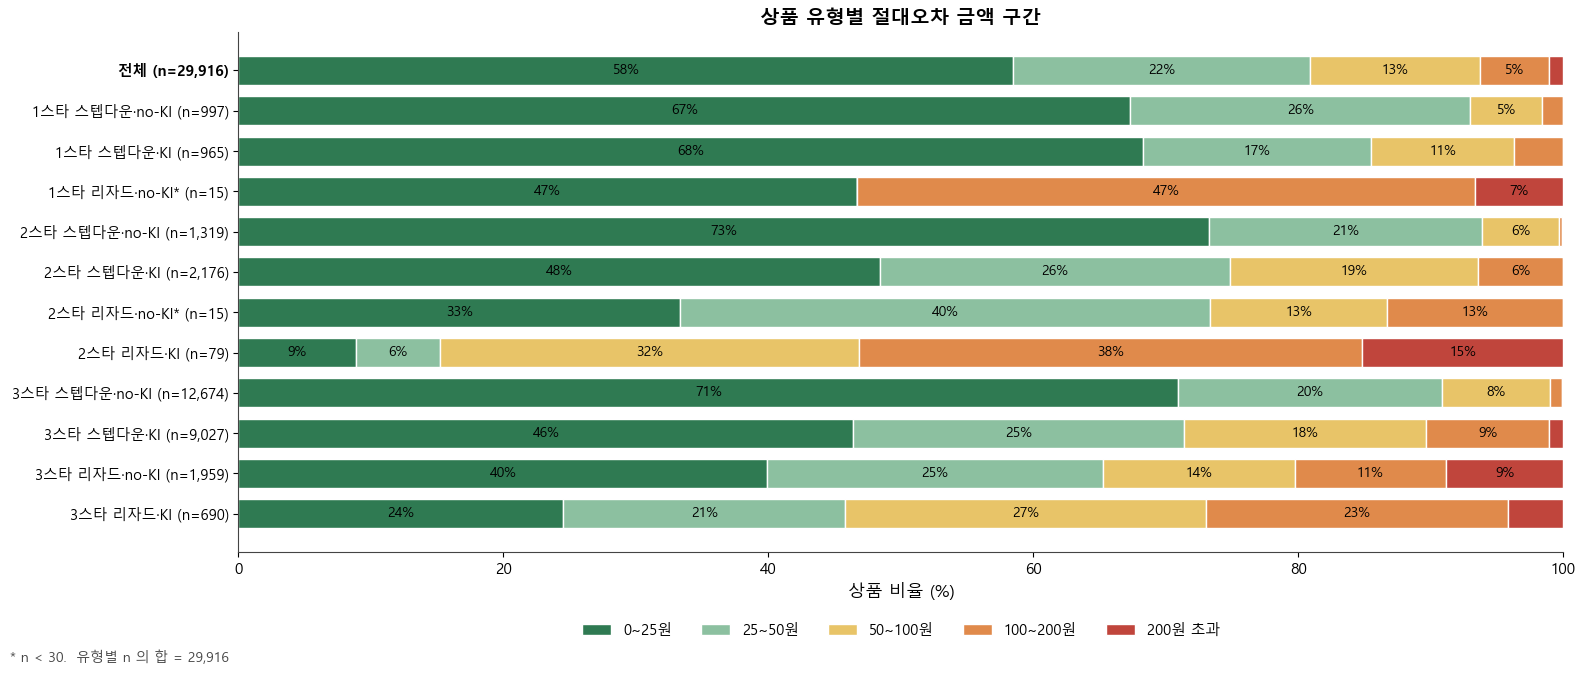

저장 result/image/fig_17_type_error_bands.png  + .csv


In [15]:
def fig_17_type_error_bands():
    bands_h(type_groups(), "fig_17_type_error_bands", "상품 유형별 절대오차 금액 구간",
            note="* n < 30.  유형별 n 의 합 = 29,916")


fig_17_type_error_bands()

## 27쪽 — 기초자산별 성능 (R² · MAPE)

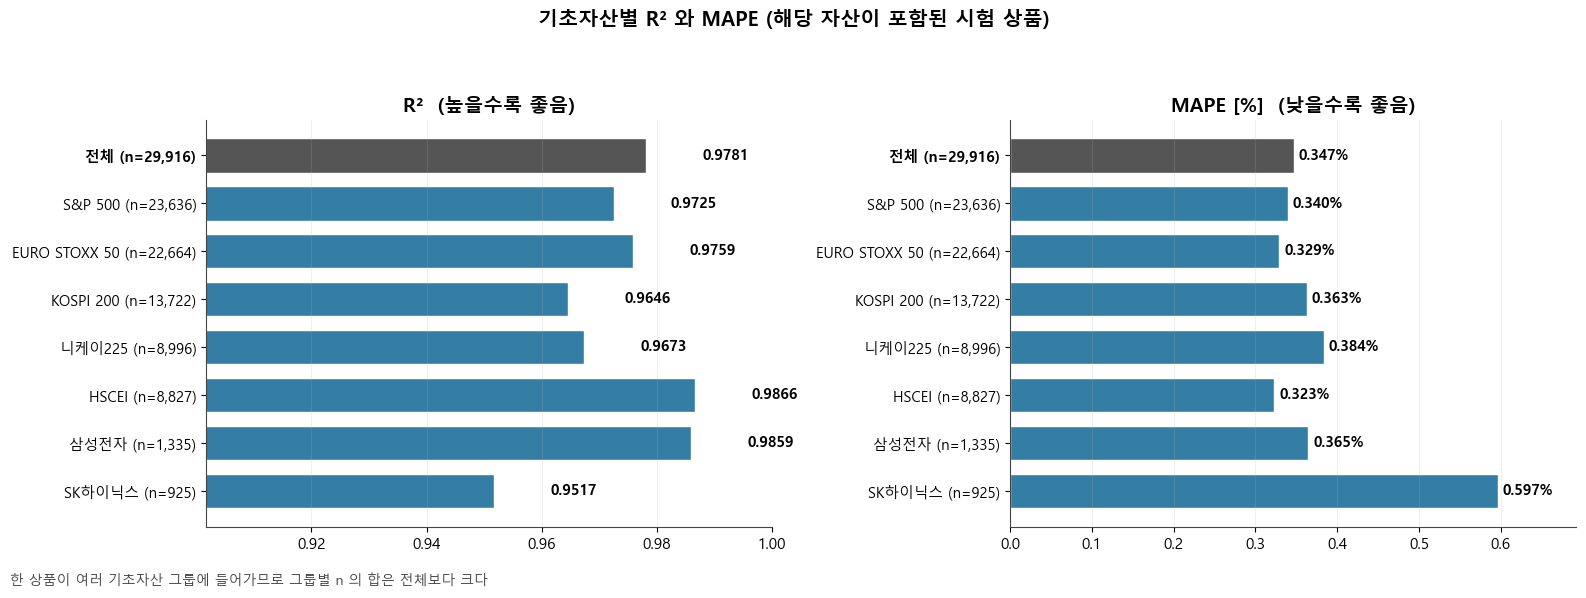

저장 result/image/fig_18_underlying_r2_mape.png  + .csv


In [16]:
def fig_18_underlying_r2_mape():
    r2_mape_h(und_groups(), "fig_18_underlying_r2_mape", "기초자산별 R² 와 MAPE (해당 자산이 포함된 시험 상품)",
              note="한 상품이 여러 기초자산 그룹에 들어가므로 그룹별 n 의 합은 전체보다 크다")


fig_18_underlying_r2_mape()

## 28쪽 — 기초자산별 절대오차 구간

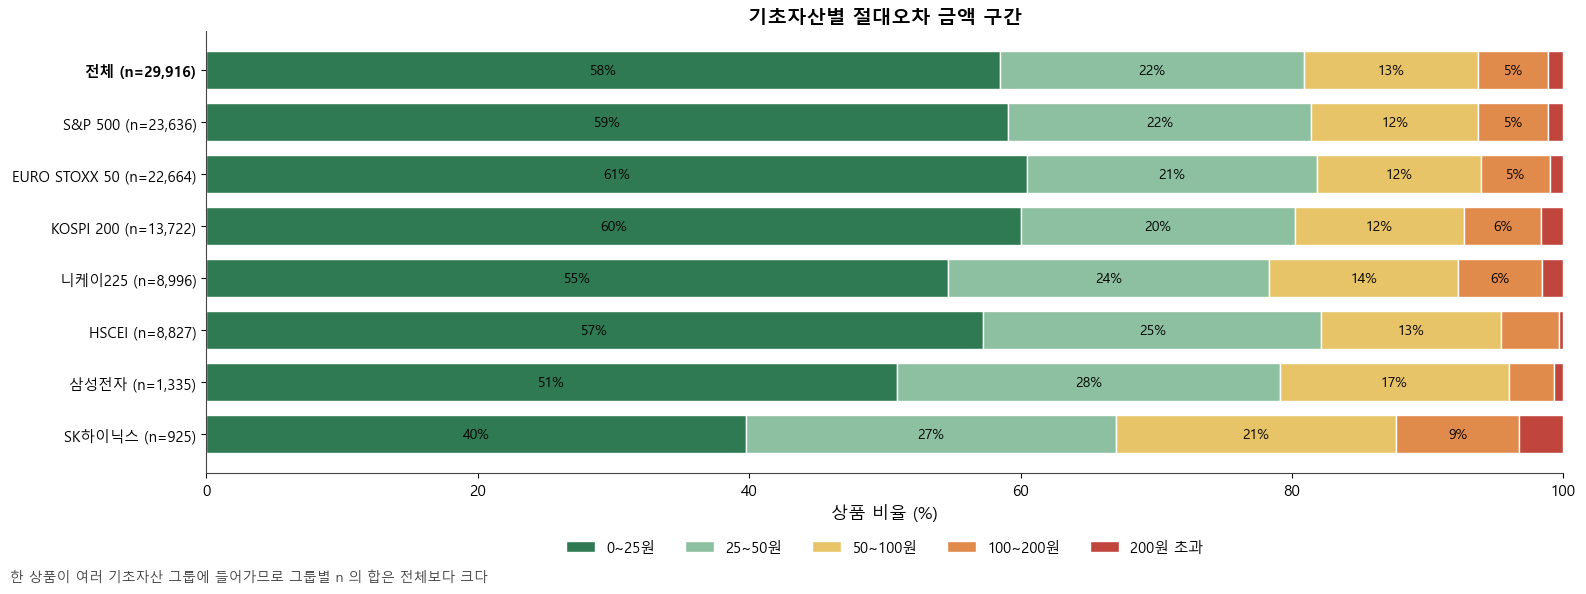

저장 result/image/fig_19_underlying_error_bands.png  + .csv


In [17]:
def fig_19_underlying_error_bands():
    bands_h(und_groups(), "fig_19_underlying_error_bands", "기초자산별 절대오차 금액 구간",
            note="한 상품이 여러 기초자산 그룹에 들어가므로 그룹별 n 의 합은 전체보다 크다")


fig_19_underlying_error_bands()

## 29쪽 — 상품별 과소·과대 예측

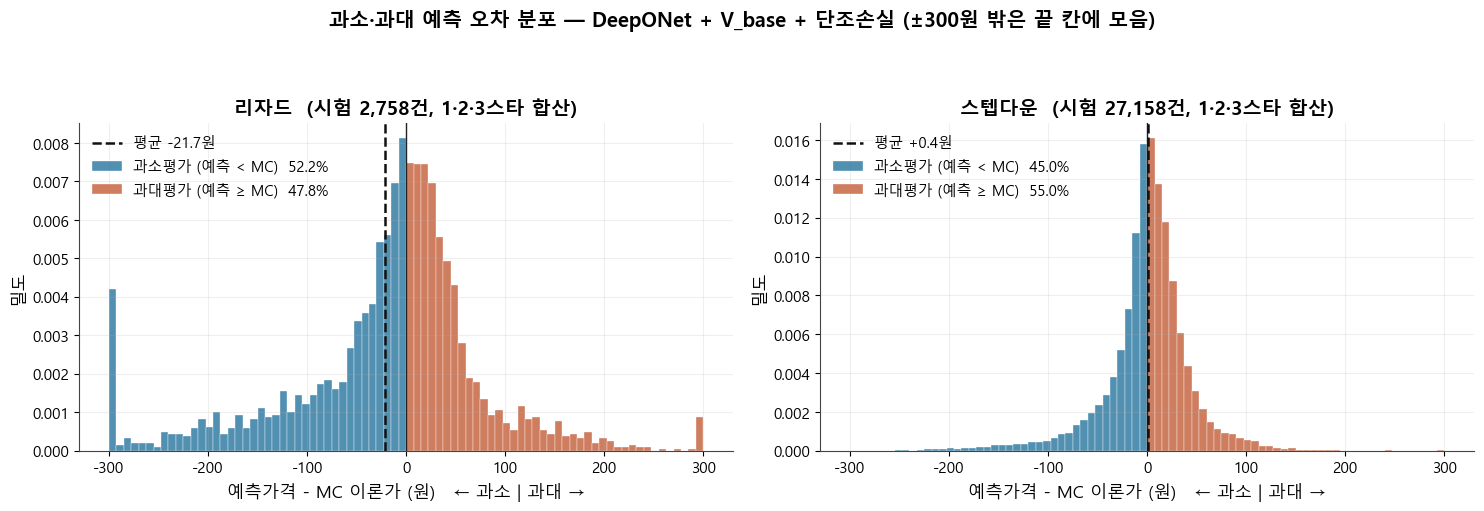

저장 result/image/fig_20_signed_lz_sd.png  + .csv


In [18]:
def fig_20_signed_lz_sd() -> None:
    """과소·과대 예측 오차 분포 — 1·2·3스타 합산, 리자드와 스텝다운 두 패널. 제안 모형."""
    B = bundle()
    oos, mc, P, has_lz = B["oos"], B["mc"], B["P"], B["has_lz"]
    e_all = P[MAIN][oos] - mc[oos]
    fig, axes = plt.subplots(1, 2, figsize=(15.0, 5.2), sharey=False)
    bins = np.linspace(-300, 300, 81)
    rows = []
    for ax, (lab, m) in zip(axes, (("리자드", has_lz[oos]), ("스텝다운", ~has_lz[oos]))):
        e = e_all[m]
        h, ed = np.histogram(np.clip(e, bins[0], bins[-1]), bins=bins, density=True)
        ctr = (ed[:-1] + ed[1:]) / 2
        ax.bar(ctr[ctr < 0], h[ctr < 0], width=ed[1] - ed[0], color="#347da5", alpha=0.85,
               edgecolor="white", lw=0.3, label="과소평가 (예측 < MC)  {:.1f}%".format((e < 0).mean() * 100))
        ax.bar(ctr[ctr >= 0], h[ctr >= 0], width=ed[1] - ed[0], color="#c76643", alpha=0.85,
               edgecolor="white", lw=0.3, label="과대평가 (예측 ≥ MC)  {:.1f}%".format((e >= 0).mean() * 100))
        ax.axvline(0, color="#222222", lw=1.0)
        ax.axvline(e.mean(), color="#111111", lw=1.8, ls="--", label="평균 {:+.1f}원".format(e.mean()))
        ax.set_title("{}  (시험 {:,}건, 1·2·3스타 합산)".format(lab, int(m.sum())), fontweight="bold")
        ax.set_xlabel("예측가격 - MC 이론가 (원)   ← 과소 | 과대 →")
        ax.set_ylabel("밀도")
        ax.legend(frameon=False, fontsize=10.5, loc="upper left")
        ax.grid(alpha=0.2)
        rows.append({"구조": lab, "n": int(m.sum()), "평균 오차(원)": float(e.mean()),
                     "중위 오차(원)": float(np.median(e)),
                     "과소 비율(%)": float((e < 0).mean() * 100), "과대 비율(%)": float((e >= 0).mean() * 100),
                     "100원 초과 과소(%)": float((e < -100).mean() * 100),
                     "100원 초과 과대(%)": float((e > 100).mean() * 100)})
    fig.suptitle("과소·과대 예측 오차 분포 — DeepONet + V_base + 단조손실 (±300원 밖은 끝 칸에 모음)",
                 fontsize=14.5, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.92])
    save(fig, "fig_20_signed_lz_sd", pd.DataFrame(rows))


fig_20_signed_lz_sd()

## 30–32쪽 — 계약조건별 가격: 조건 하나만 변경 (1·2·3스타)

같은 상품에서 계약조건 하나만 단계별로 바꾸고 MC · 제안 모형 · XGBoost 를 다시 계산해 단계마다 평균합니다. 상품 집합은 단계마다 같습니다 (시험 전수, 리자드 조건은 리자드 상품 전수). KI 배리어 1.0 은 노낙인이라 선으로 잇지 않습니다.

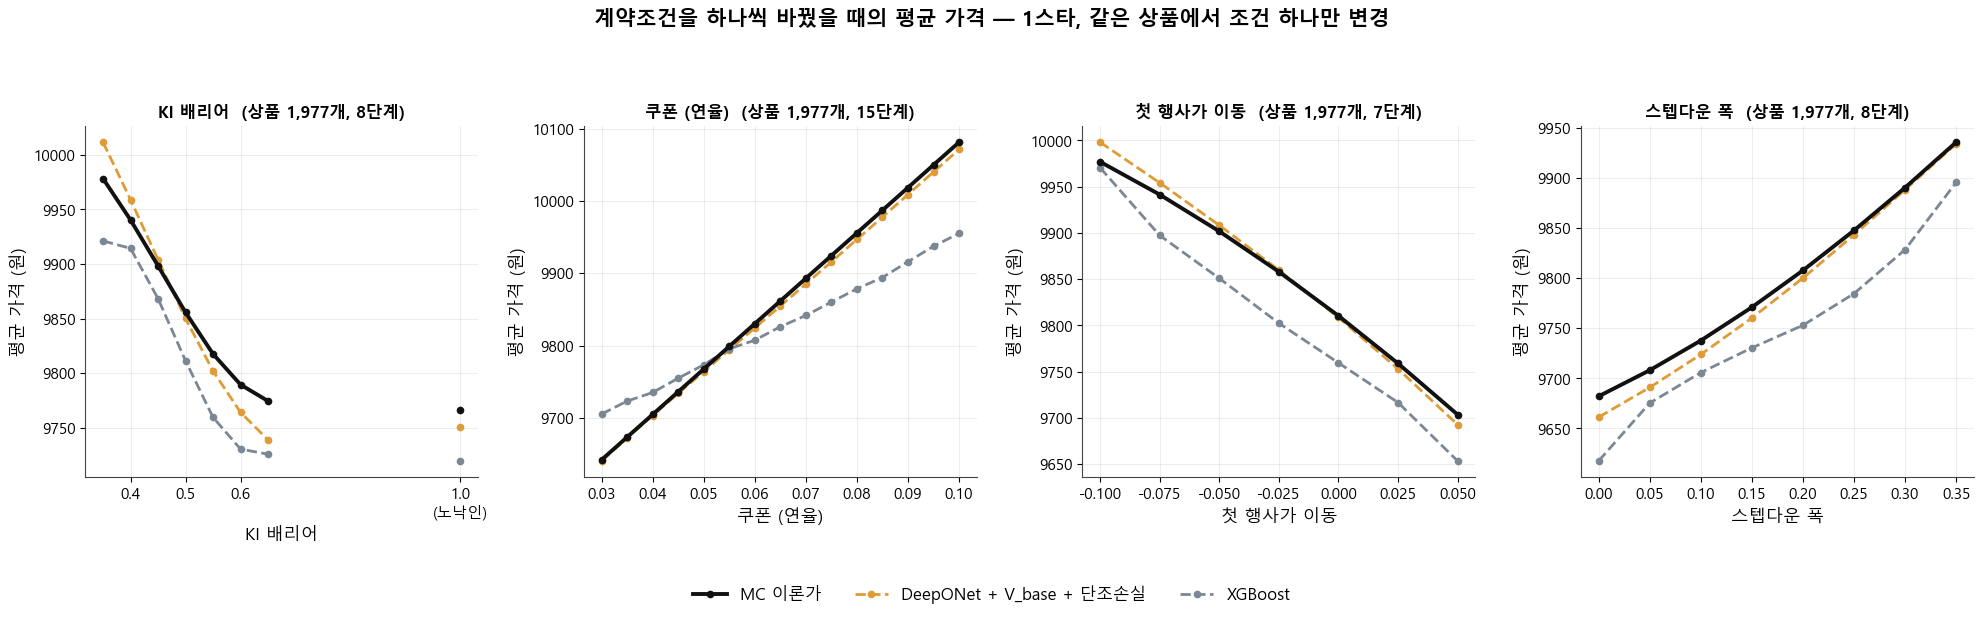

저장 result/image/fig_13p_contract_perturb_1star.png  + .csv


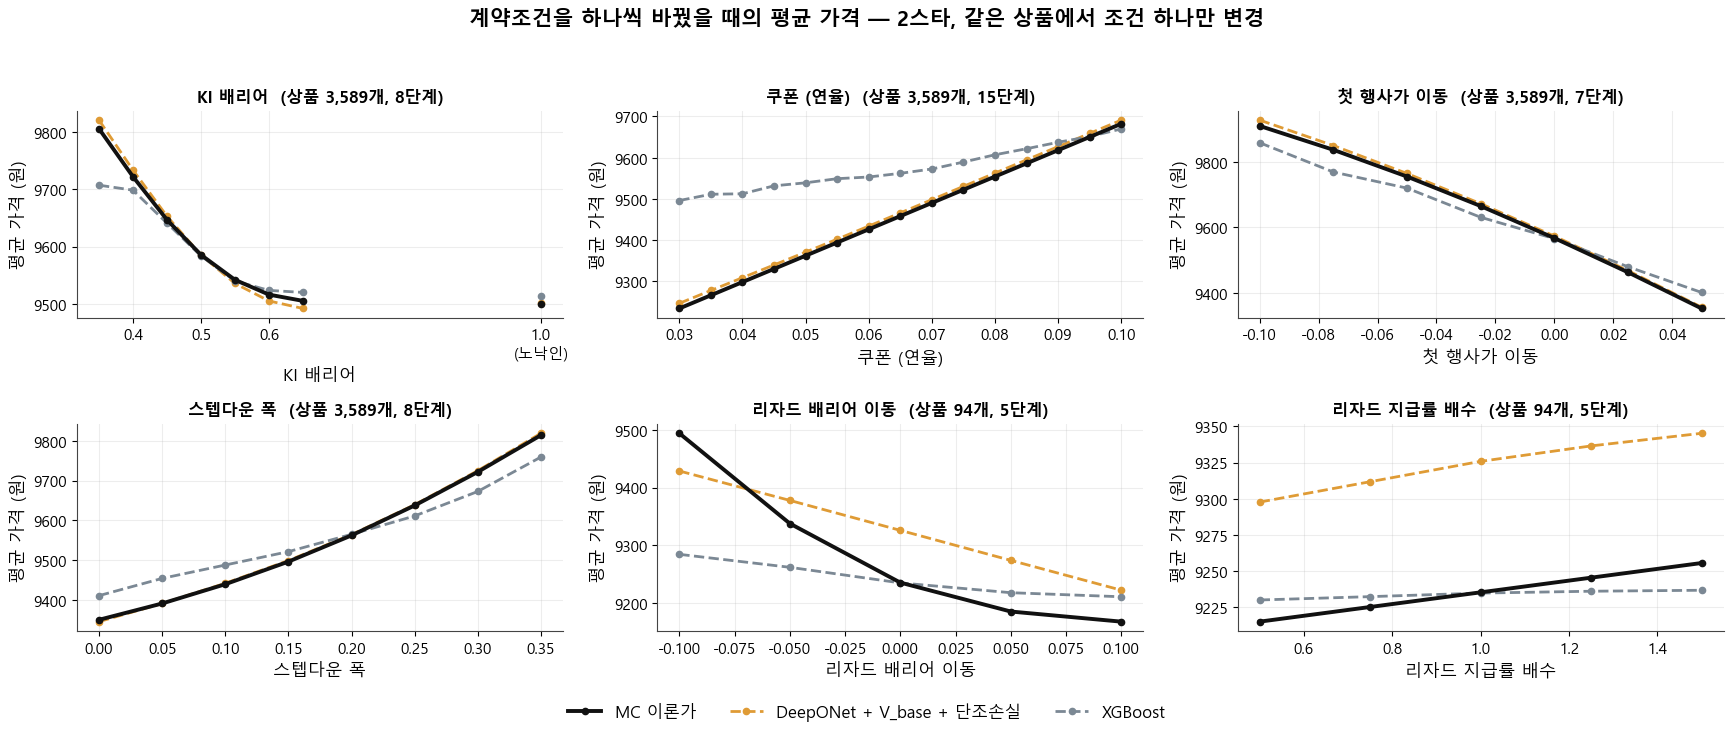

저장 result/image/fig_13p_contract_perturb_2star.png  + .csv


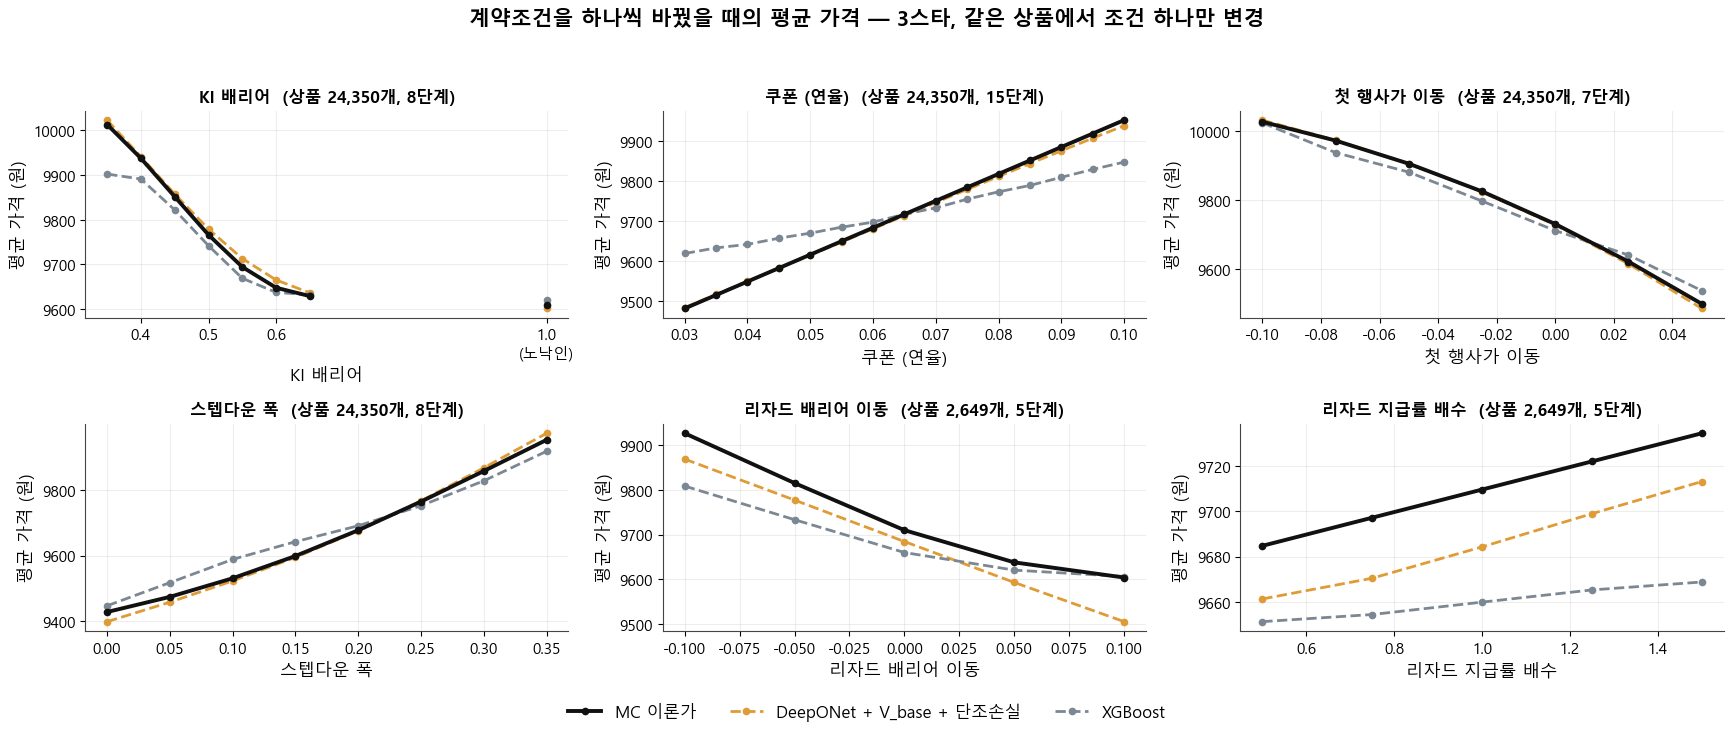

저장 result/image/fig_13p_contract_perturb_3star.png  + .csv


In [19]:
SRC = fm.CACHE


FACS = ["barrier", "coupon", "strike_shift", "spread", "lz_shift", "lz_pmt_scale"]


TITLE = {"barrier": "KI 배리어", "coupon": "쿠폰 (연율)", "strike_shift": "첫 행사가 이동",
         "spread": "스텝다운 폭", "lz_shift": "리자드 배리어 이동", "lz_pmt_scale": "리자드 지급률 배수"}


LINES = [("MC", "MC 이론가", C["MC"], "-", 2.8), (MAIN, "DeepONet + V_base + 단조손실", C[MAIN], "--", 2.0),
         ("XGBoost", "XGBoost", C["XGBoost"], "--", 2.0)]


def lplot(ax, f, lv, y, *args, **kw):
    """수준별 곡선. KI 배리어 1.0 은 노낙인(구조가 바뀜, 0.65~1.0 사이 수준 없음)이라 선으로 잇지 않고 점만."""
    lv, y = np.asarray(lv, float), np.asarray(y, float)
    if f != "barrier" or not (lv >= 1.0).any():
        return ax.plot(lv, y, *args, **kw)
    m = lv < 1.0
    h = ax.plot(lv[m], y[m], *args, **kw)
    kw.pop("label", None)
    ax.plot(lv[~m], y[~m], *[a for a in args if a not in ("-", "--")], **{**kw, "ls": "none"})
    ax.set_xticks([0.4, 0.5, 0.6, 1.0])
    ax.set_xticklabels(["0.4", "0.5", "0.6", "1.0\n(노낙인)"])
    return h


def mc_table() -> pd.DataFrame:
    """조건 변경 MC (준비 2)."""
    return PERT


def predict(M: pd.DataFrame) -> pd.DataFrame:
    """M 의 (상품, 요인, 수준) 마다 최종모형 · XGBoost 예측 [원]."""
    B = bundle()
    D, fold, nstar = B["D"], B["fold"], B["nstar"]
    idx_of = {it: i for i, it in enumerate(D.ITEM)}
    nobs = np.asarray(D.nobs)
    has_lz = B["has_lz"]
    M = M.copy()
    M["i"] = M["item"].map(idx_of)
    M["fold"] = fold[M["i"].to_numpy()]
    M[MAIN] = np.nan
    M["XGBoost"] = np.nan
    don = {(s, k): _don("canon", "ball_dm", s, k) for s in range(5) for k in range(len(D.WF))}
    xgb = {(s, k): AN.load("ball_xgb", s, k, kind="xgb") for s in range(5) for k in range(len(D.WF))}
    for (f, lv, k), g in M.groupby(["factor", "level", "fold"]):
        idx = g["i"].to_numpy()
        X = CS.apply_factor(D.CON[idx], f, lv, nobs[idx], has_lz[idx])
        vb = vbase_els(X, D.VC[idx], D.CURVE[idx], nobs[idx], mode="clark", nstar=nstar[idx])
        Xf = np.concatenate([X, np.nan_to_num(vb, nan=0.0).astype("float32")[:, None]], 1).astype("float32")
        M.loc[g.index, MAIN] = np.mean([don[(s, k)](D.CURVE[idx], D.VC[idx], Xf) for s in range(5)], 0) * FACE
        M.loc[g.index, "XGBoost"] = np.mean([xgb[(s, k)](D.CURVE[idx], D.VC[idx], X) for s in range(5)], 0) * FACE
    return M


def fig_13p_contract_perturb() -> None:
    M = predict(mc_table())
    M.to_parquet(SRC / "mc_contract_perturb_pred.parquet", index=False)
    for ns in (1, 2, 3):
        Z = M[M["nstar"] == ns]
        facs = [f for f in FACS if Z[Z["factor"] == f]["item"].nunique() >= 30]
        nr = 1 if len(facs) <= 4 else 2
        if nr == 1:
            fig, axs = plt.subplots(1, 4, figsize=(20.0, 6.2), squeeze=False)
        else:
            fig, axs = plt.subplots(2, 3, figsize=(17.5, 7.4), squeeze=False)
        rows = []
        for ax, f in zip(axs.ravel(), facs):
            z = Z[Z["factor"] == f]
            n_it = z["item"].nunique()
            # 모든 수준에 값이 있는 상품만 — 수준마다 같은 상품 집합
            full = z.groupby("item")["level"].nunique() == z["level"].nunique()
            z = z[z["item"].isin(full[full].index)]
            for key, lab, col, ls, lw in LINES:
                col_ = "mc" if key == "MC" else key
                g = z.groupby("level")[col_].mean().sort_index()
                lplot(ax, f, g.index, g.values, ls, marker="o", color=col, lw=lw, ms=4.5, label=lab,
                      zorder=6 if key == "MC" else 3)
                rows += [{"스타": ns, "계약조건": TITLE[f], "수준": float(l), "n": int(z["item"].nunique()),
                          "모형": lab, "평균 가격(원)": float(v)} for l, v in g.items()]
            ax.set_title("{}  (상품 {:,}개, {}단계)".format(TITLE[f], z["item"].nunique(), z["level"].nunique()),
                         fontweight="bold", fontsize=12)
            if z["item"].nunique() != n_it:
                print("  {}스타 {}: 수준 누락 상품 {}건 제외".format(ns, f, n_it - z["item"].nunique()))
            ax.set_xlabel(TITLE[f])
            ax.set_ylabel("평균 가격 (원)")
            ax.grid(alpha=0.22)
        for a in axs.ravel()[len(facs):]:
            a.axis("off")
        h, l = axs.ravel()[0].get_legend_handles_labels()
        fig.legend(h, l, loc="lower center", ncol=3, frameon=False, fontsize=12)
        fig.suptitle("계약조건을 하나씩 바꿨을 때의 평균 가격 — {}스타, 같은 상품에서 조건 하나만 변경".format(ns),
                     fontsize=15, fontweight="bold")
        fig.tight_layout(rect=[0, 0.09 if nr == 1 else 0.05, 1, 0.92 if nr == 1 else 0.95])
        save(fig, "fig_13p_contract_perturb_{}star".format(ns), pd.DataFrame(rows))


fig_13p_contract_perturb()

## 33–35쪽 — 계약조건별 가격: 구간평균 (1·2·3스타)

시험 상품을 실제 계약조건 값의 십분위 구간으로 나눠 구간별 평균 가격을 비교합니다. 구간마다 상품이 달라 다른 조건의 차이가 섞입니다 (30–32쪽과 다른 질문).

C:\Users\Juhwankim\Documents\Github\PI-DeepONet-ELS\generate\eval_cross_section.py:116: RuntimeWarning: All-NaN slice encountered
  lzb = np.nanmin(np.where(on, D.CON[:, CS.iLB], np.nan), 1)
C:\Users\Juhwankim\Documents\Github\PI-DeepONet-ELS\generate\eval_cross_section.py:117: RuntimeWarning: All-NaN slice encountered
  lzp = np.nanmax(np.where(on, D.CON[:, CS.iLP], np.nan), 1)


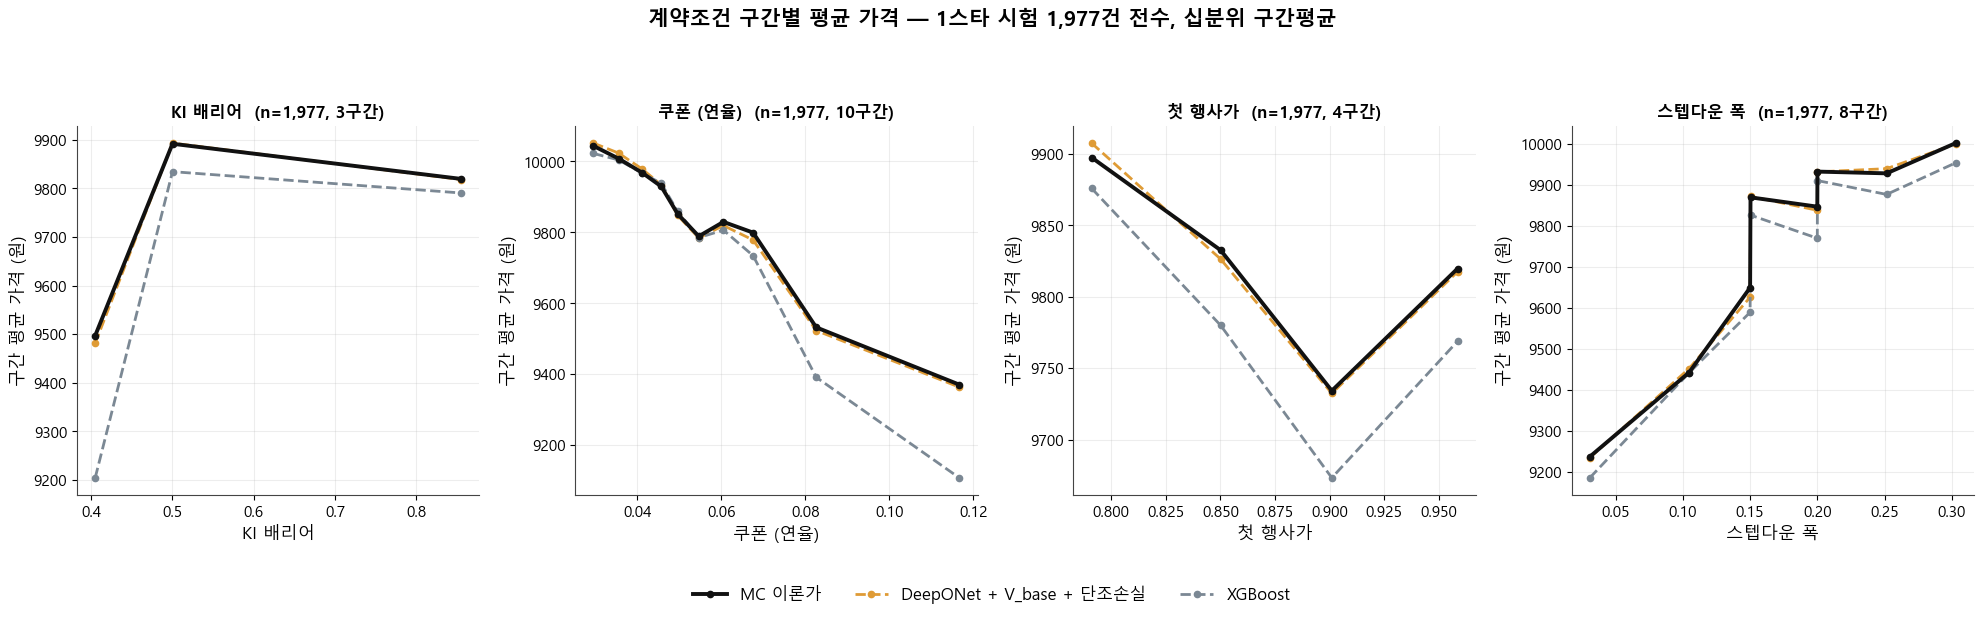

저장 result/image/fig_13_contract_response_1star.png  + .csv


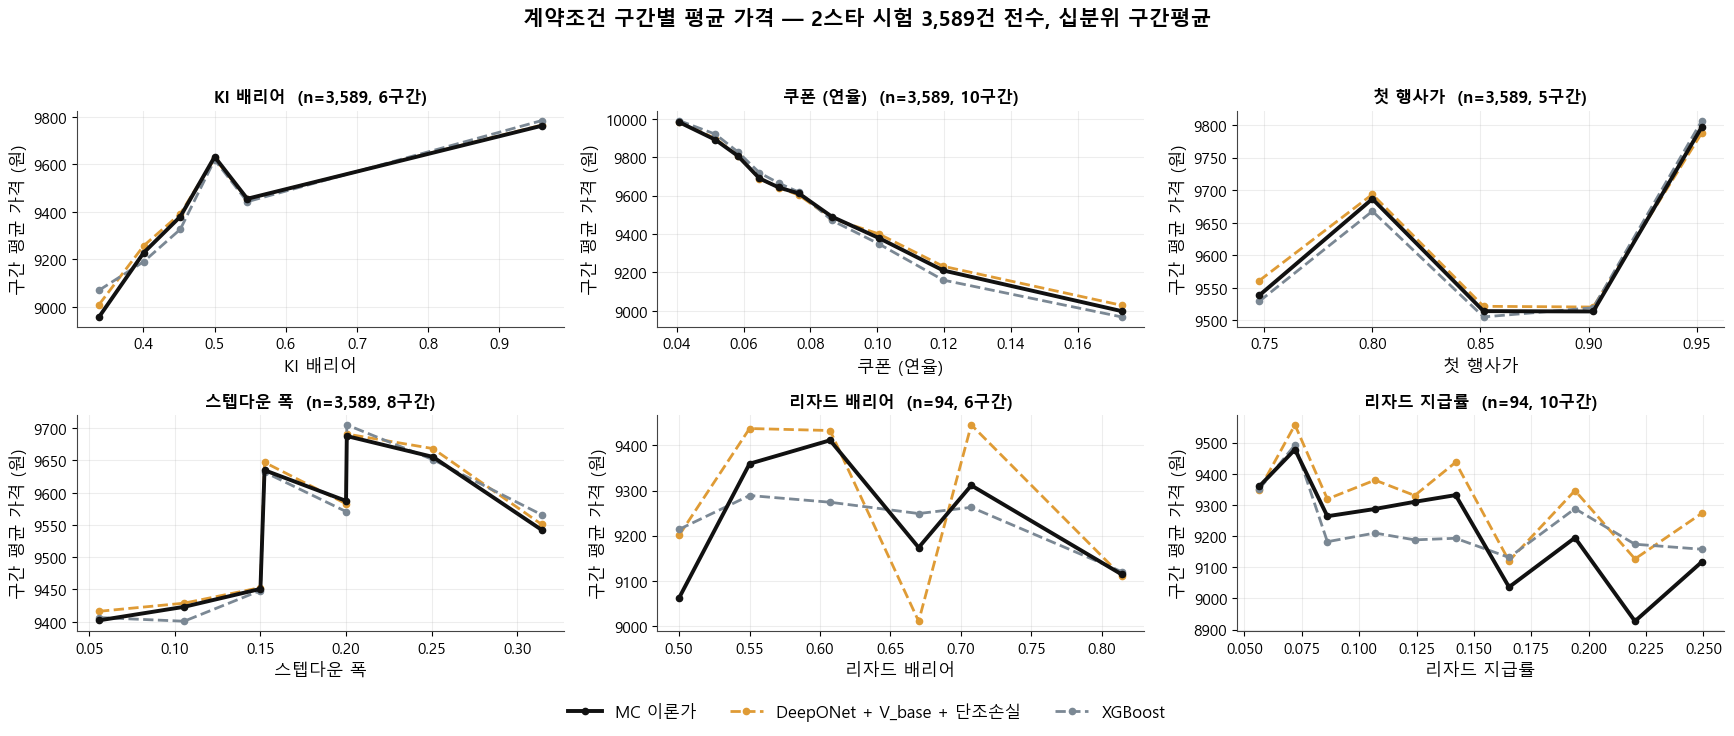

저장 result/image/fig_13_contract_response_2star.png  + .csv


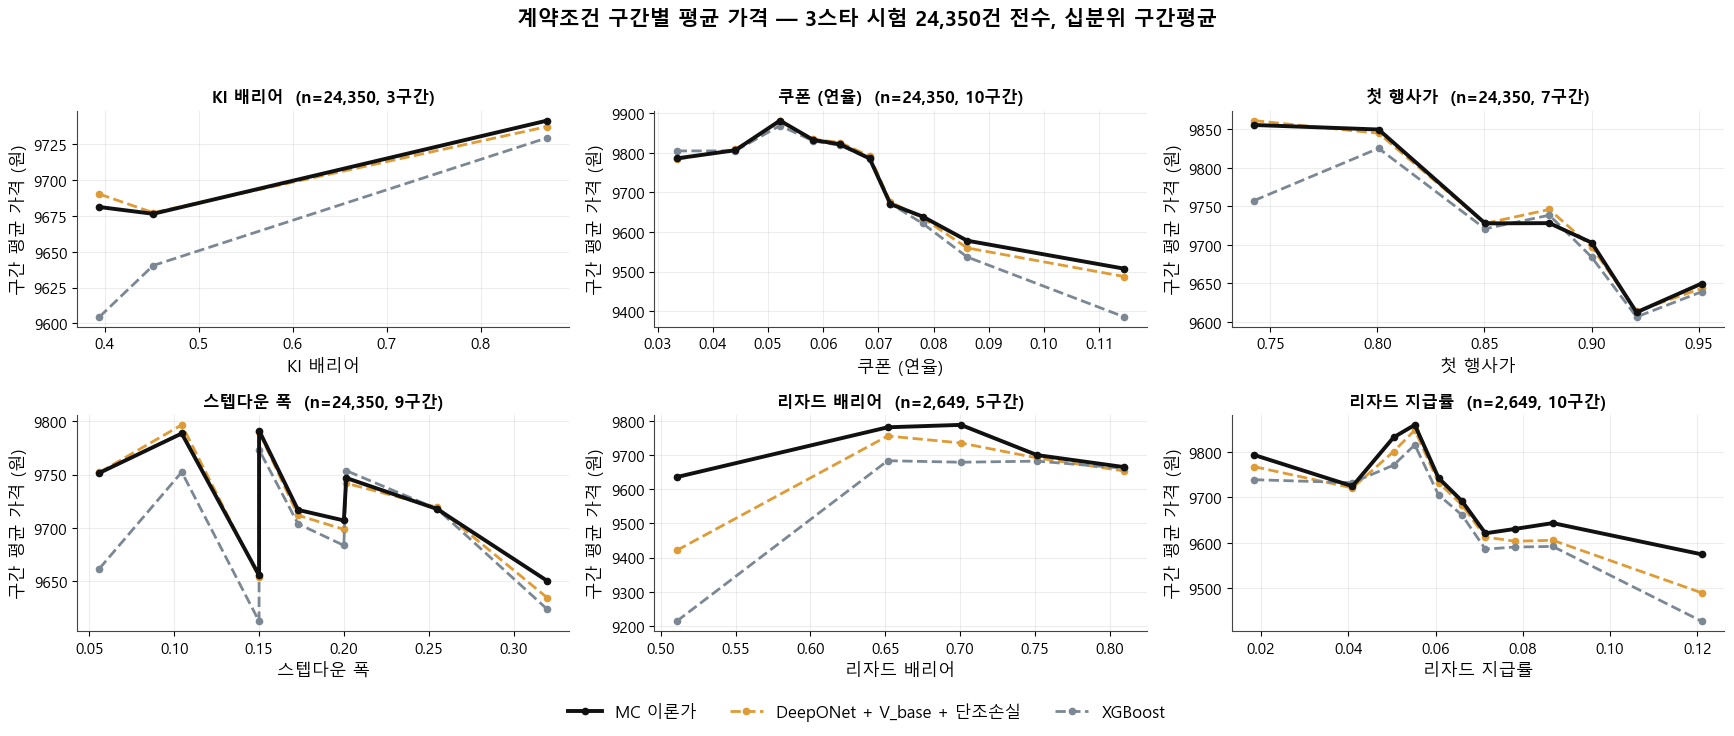

저장 result/image/fig_13_contract_response_3star.png  + .csv


In [20]:
def fig_13_12_binned_all_oos() -> None:
    """시험 29,916건 전수 — 계약조건 십분위 구간평균. 13: 가격 (MC·최종·XGB), 12: 오차 (최종·XGB)."""
    from generate.eval_cross_section import build_terms
    B = bundle()
    D, oos, mc, P, nstar = B["D"], B["oos"], B["mc"], B["P"], B["nstar"]
    terms = build_terms(D)
    lines = [("MC", "MC 이론가", C["MC"], "-", 2.8), (MAIN, "DeepONet + V_base + 단조손실", C[MAIN], "--", 2.0),
             ("XGBoost", "XGBoost", C["XGBoost"], "--", 2.0)]
    for ns in (1, 2, 3):
        S = oos[nstar[oos] == ns]
        facs = [f for f in TERM_KR if np.isfinite(terms[f][S]).sum() >= 30
                and len(np.unique(terms[f][S][np.isfinite(terms[f][S])])) > 1]
        nr = 1 if len(facs) <= 4 else 2
        if nr == 1:
            figP, axP = plt.subplots(1, 4, figsize=(20.0, 6.2), squeeze=False)
        else:
            figP, axP = plt.subplots(2, 3, figsize=(17.5, 7.4), squeeze=False)
        figE, axE = plt.subplots(2, 3, figsize=(16.0, 8.2))
        rowsP, rowsE = [], []
        for aP, aE, f in zip(axP.ravel(), axE.ravel(), facs):
            i = S[np.isfinite(terms[f][S])]
            x = terms[f][i]
            b, nb = _binned(x)
            cx = np.array([x[b == j].mean() for j in range(nb) if (b == j).any()])
            keep = [j for j in range(nb) if (b == j).any()]
            cnt = [int((b == j).sum()) for j in keep]
            for key, lab, col, ls, lw in lines:
                y = mc[i] if key == "MC" else P[key][i]
                v = np.array([y[b == j].mean() for j in keep])
                aP.plot(cx, v, ls, marker="o", color=col, lw=lw, ms=4.5, label=lab, zorder=6 if key == "MC" else 3)
                rowsP += [{"스타": ns, "계약조건": TERM_KR[f], "구간중심": float(c), "n": n_, "모형": lab,
                           "평균 가격(원)": float(vv)} for c, n_, vv in zip(cx, cnt, v)]
                if key == "MC":
                    continue
                e = P[key][i] - mc[i]
                m_ = np.array([e[b == j].mean() for j in keep])
                se = np.array([e[b == j].std(ddof=1) / np.sqrt(max((b == j).sum(), 2)) for j in keep])
                aE.plot(cx, m_, "-", marker="o", color=col, lw=2.0, ms=4.5, label=lab)
                aE.fill_between(cx, m_ - se, m_ + se, color=col, alpha=0.15, lw=0)
                rowsE += [{"스타": ns, "계약조건": TERM_KR[f], "구간중심": float(c), "n": n_, "모형": lab,
                           "평균 오차(원)": float(mm), "표준오차(원)": float(ss)}
                          for c, n_, mm, ss in zip(cx, cnt, m_, se)]
            aE.axhline(0, color=C["MC"], lw=2.2, label="MC 이론가 (오차 0)")
            for a in (aP, aE):
                a.set_title("{}  (n={:,}, {}구간)".format(TERM_KR[f], len(i), len(keep)), fontweight="bold", fontsize=12)
                a.set_xlabel(TERM_KR[f])
                a.grid(alpha=0.22)
            aP.set_ylabel("구간 평균 가격 (원)")
            aE.set_ylabel("구간 평균 오차 (원)")
        plt.close(figE)
        for fig, axs, name, ttl, rows in (
                (figP, axP, "fig_13_contract_response_{}star".format(ns), "계약조건 구간별 평균 가격", rowsP),):
            for a in axs.ravel()[len(facs):]:
                a.axis("off")
            h, l = axs.ravel()[0].get_legend_handles_labels()
            fig.legend(h, l, loc="lower center", ncol=3, frameon=False, fontsize=12)
            fig.suptitle("{} — {}스타 시험 {:,}건 전수, 십분위 구간평균".format(ttl, ns, len(S)),
                         fontsize=15, fontweight="bold")
            fig.tight_layout(rect=[0, 0.09 if nr == 1 else 0.05, 1, 0.92 if nr == 1 else 0.95])
            save(fig, name, pd.DataFrame(rows))


fig_13_12_binned_all_oos()

## 36–38쪽 — 계약조건별 평균 예측 편향 (1·2·3스타)

시험 전수의 실제 오차(예측 − MC)를 33–35쪽과 같은 구간으로 평균합니다. 띠 = 구간 안 상품 간 ±1 표준편차.

C:\Users\Juhwankim\Documents\Github\PI-DeepONet-ELS\generate\eval_cross_section.py:116: RuntimeWarning: All-NaN slice encountered
  lzb = np.nanmin(np.where(on, D.CON[:, CS.iLB], np.nan), 1)
C:\Users\Juhwankim\Documents\Github\PI-DeepONet-ELS\generate\eval_cross_section.py:117: RuntimeWarning: All-NaN slice encountered
  lzp = np.nanmax(np.where(on, D.CON[:, CS.iLP], np.nan), 1)


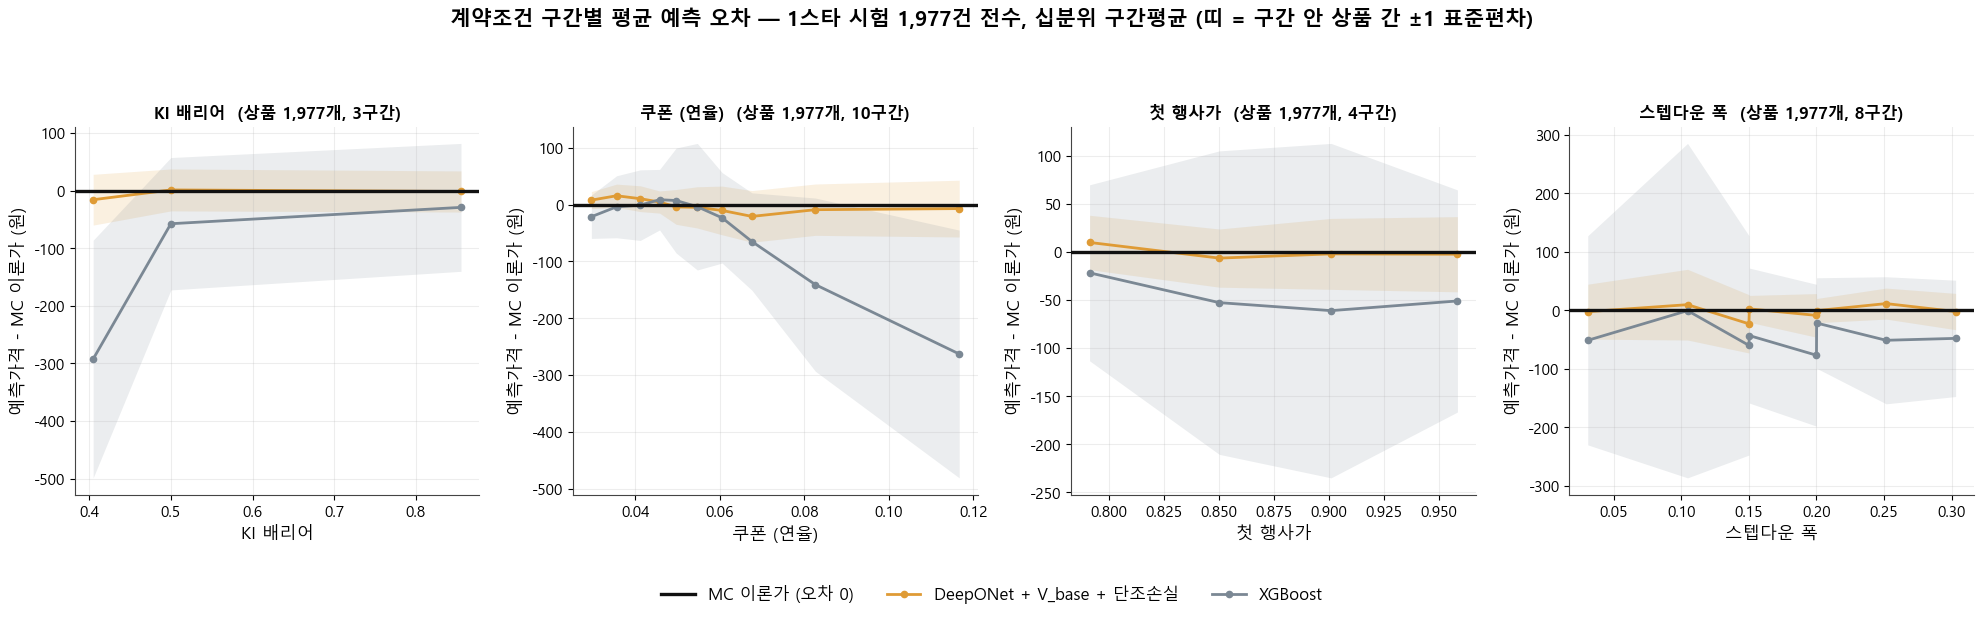

저장 result/image/fig_12b_error_binned_1star.png  + .csv


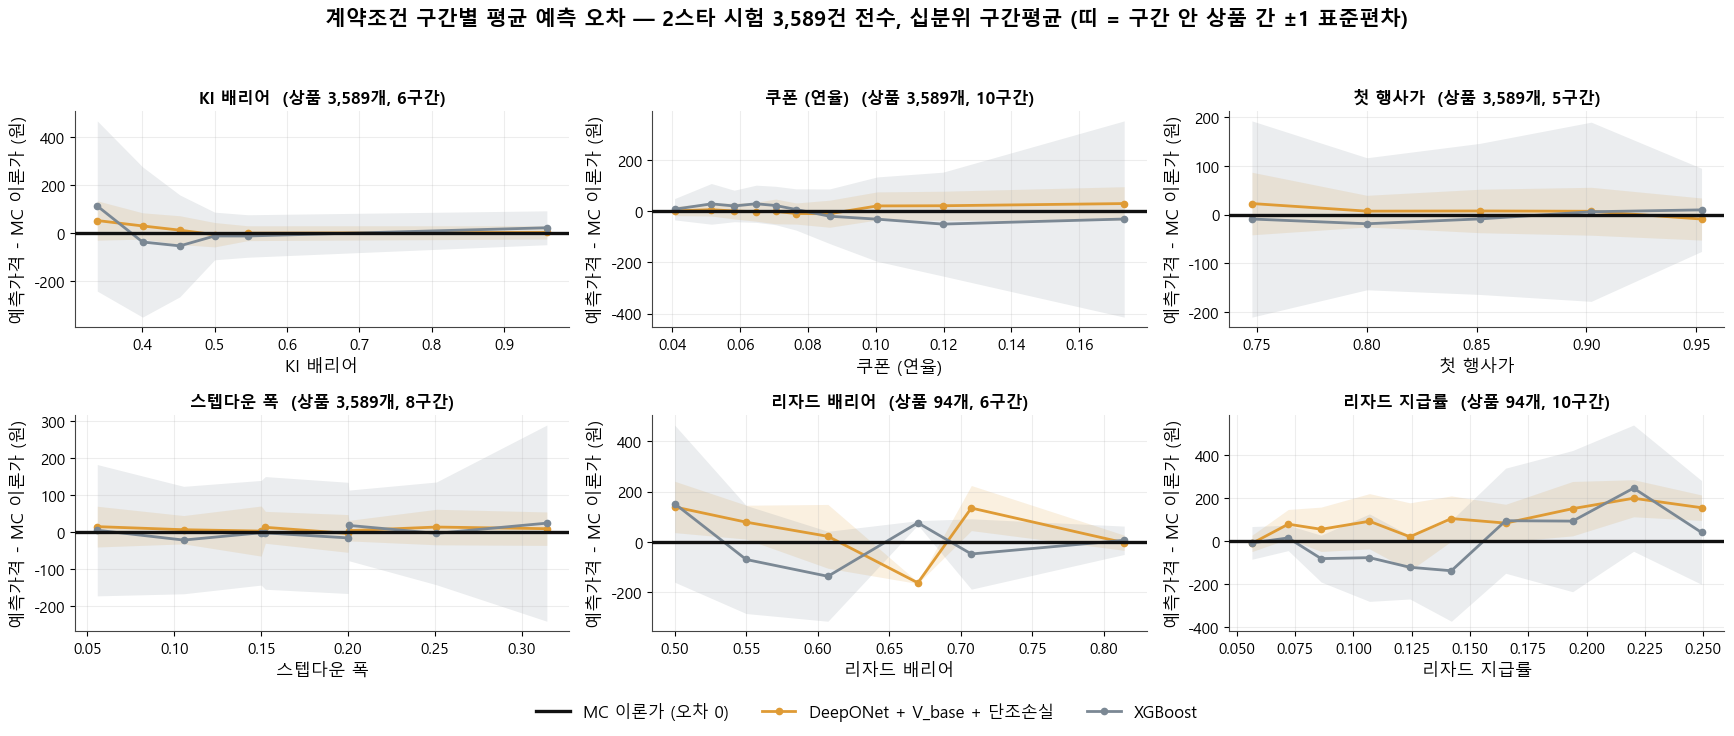

저장 result/image/fig_12b_error_binned_2star.png  + .csv


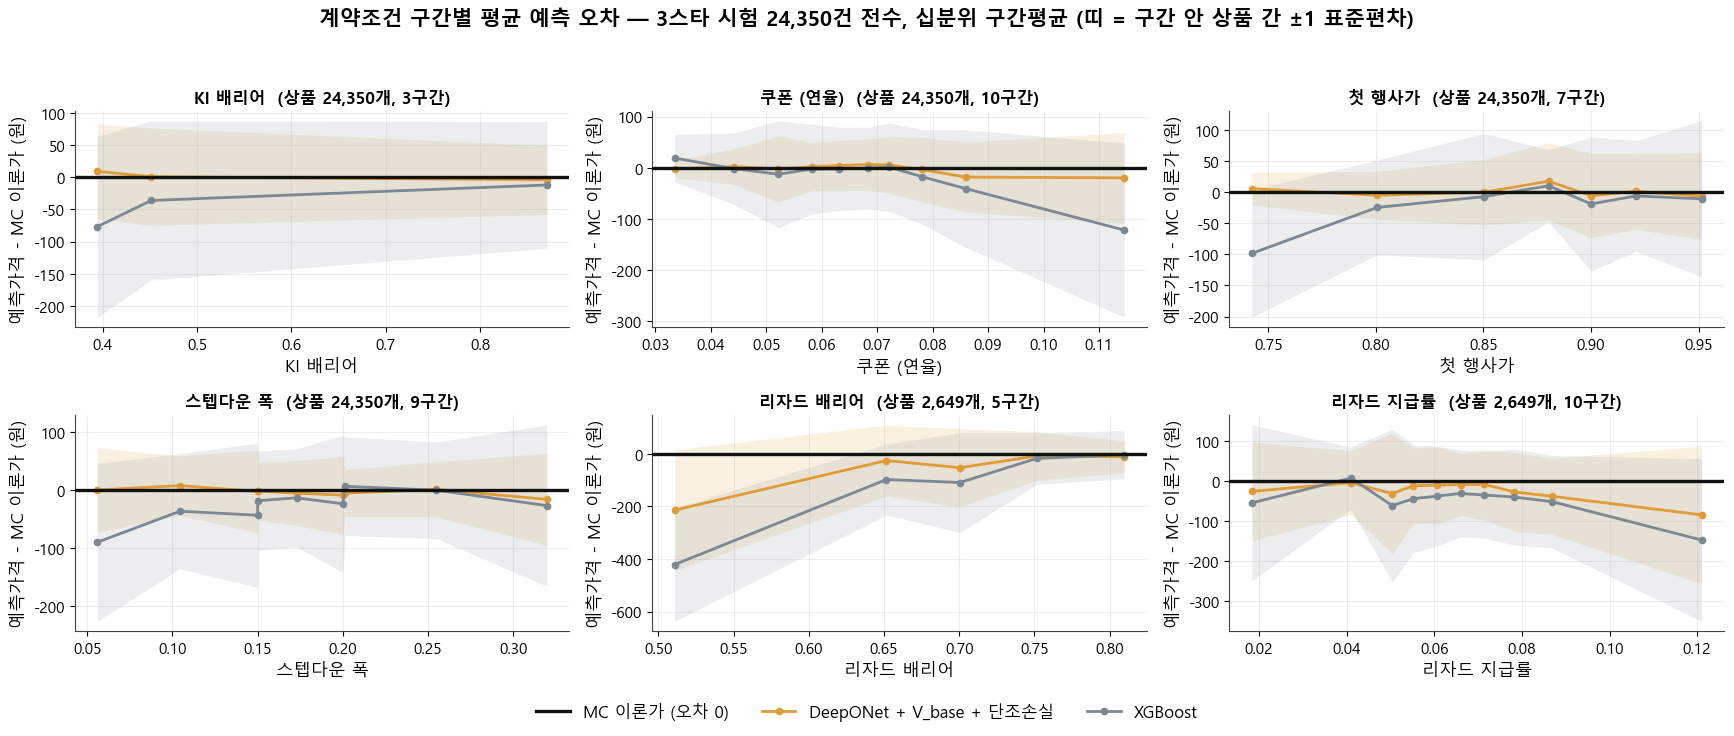

저장 result/image/fig_12b_error_binned_3star.png  + .csv
 스타  상품 수  최대 |구간 평균 오차| 제안(원)  최대 |구간 평균 오차| XGB(원)
  1  1977                 23.2                 292.4
  2  3589                199.9                 247.0
  3 24350                214.3                 421.3


In [21]:
def fig_12b_error_binned() -> None:
    """계약조건 구간별 평균 예측 오차 (모형 − MC) — 시험 전수, 30~32쪽과 같은 구간.

    새 계산 없이 실제 OOS 예측(bundle)과 정본 MC 로 그린다. 띠 = 구간 안 상품 간 ±1 표준편차.
    """
    B = bundle()
    D, oos, mc, P, nstar = B["D"], B["oos"], B["mc"], B["P"], B["nstar"]
    terms = build_terms(D)
    models = [(MAIN, "DeepONet + V_base + 단조손실"), ("XGBoost", "XGBoost")]
    summ = []
    for ns in (1, 2, 3):
        S = oos[nstar[oos] == ns]
        facs = [f for f in TERM_KR if np.isfinite(terms[f][S]).sum() >= 30
                and len(np.unique(terms[f][S][np.isfinite(terms[f][S])])) > 1]
        nr = 1 if len(facs) <= 4 else 2
        if nr == 1:
            fig, axs = plt.subplots(1, 4, figsize=(20.0, 6.2), squeeze=False)
        else:
            fig, axs = plt.subplots(2, 3, figsize=(17.5, 7.4), squeeze=False)
        rows, mx = [], {k: 0.0 for k, _ in models}
        for ax, f in zip(axs.ravel(), facs):
            i = S[np.isfinite(terms[f][S])]
            x = terms[f][i]
            b, nb = _binned(x)
            keep = [j for j in range(nb) if (b == j).any()]
            cx = np.array([x[b == j].mean() for j in keep])
            ax.axhline(0, color=C["MC"], lw=2.4, label="MC 이론가 (오차 0)", zorder=6)
            for key, lab in models:
                e = P[key][i] - mc[i]
                m_ = np.array([e[b == j].mean() for j in keep])
                sd = np.array([e[b == j].std(ddof=1) if (b == j).sum() > 1 else 0.0 for j in keep])
                ax.plot(cx, m_, "-", marker="o", color=C[key], lw=2.0, ms=4.5, label=lab, zorder=4)
                ax.fill_between(cx, m_ - sd, m_ + sd, color=C[key], alpha=0.15, lw=0)
                mx[key] = max(mx[key], float(np.abs(m_).max()))
                rows += [{"스타": ns, "계약조건": TERM_KR[f], "구간중심": float(c), "n": int((b == j).sum()),
                          "모형": lab, "평균 오차(원)": float(mm), "표준편차(원)": float(ss)}
                         for c, j, mm, ss in zip(cx, keep, m_, sd)]
            ax.set_title("{}  (상품 {:,}개, {}구간)".format(TERM_KR[f], len(i), len(keep)),
                         fontweight="bold", fontsize=12)
            ax.set_xlabel(TERM_KR[f])
            ax.set_ylabel("예측가격 - MC 이론가 (원)")
            ax.grid(alpha=0.22)
        for a in axs.ravel()[len(facs):]:
            a.axis("off")
        h, l = axs.ravel()[0].get_legend_handles_labels()
        fig.legend(h, l, loc="lower center", ncol=3, frameon=False, fontsize=12)
        fig.suptitle("계약조건 구간별 평균 예측 오차 — {}스타 시험 {:,}건 전수, 십분위 구간평균 "
                     "(띠 = 구간 안 상품 간 ±1 표준편차)".format(ns, len(S)), fontsize=15, fontweight="bold")
        fig.tight_layout(rect=[0, 0.09 if nr == 1 else 0.05, 1, 0.92 if nr == 1 else 0.95])
        save(fig, "fig_12b_error_binned_{}star".format(ns), pd.DataFrame(rows))
        summ.append({"스타": ns, "상품 수": len(S), "최대 |구간 평균 오차| 제안(원)": mx[MAIN],
                     "최대 |구간 평균 오차| XGB(원)": mx["XGBoost"]})
    pd.DataFrame(summ).to_csv(IMG / "fig_12b_error_binned_summary.csv", index=False,
                              encoding="utf-8-sig")
    print(pd.DataFrame(summ).round(1).to_string(index=False))


fig_12b_error_binned()

## 별첨 A–F — 상품별 MC 곡선

계약조건마다 한 장: 회색 점 = 실제 상품(실제 조건 값), 회색 선 = 그 상품에서 조건만 바꾼 MC (무작위 300개), 초록 = 상품별 곡선의 평균. 순서는 A KI 배리어 · B 쿠폰 · C 첫 행사가 · D 스텝다운 폭 · E 리자드 배리어 · F 리자드 지급률.

C:\Users\Juhwankim\Documents\Github\PI-DeepONet-ELS\generate\eval_cross_section.py:116: RuntimeWarning: All-NaN slice encountered
  lzb = np.nanmin(np.where(on, D.CON[:, CS.iLB], np.nan), 1)
C:\Users\Juhwankim\Documents\Github\PI-DeepONet-ELS\generate\eval_cross_section.py:117: RuntimeWarning: All-NaN slice encountered
  lzp = np.nanmax(np.where(on, D.CON[:, CS.iLP], np.nan), 1)


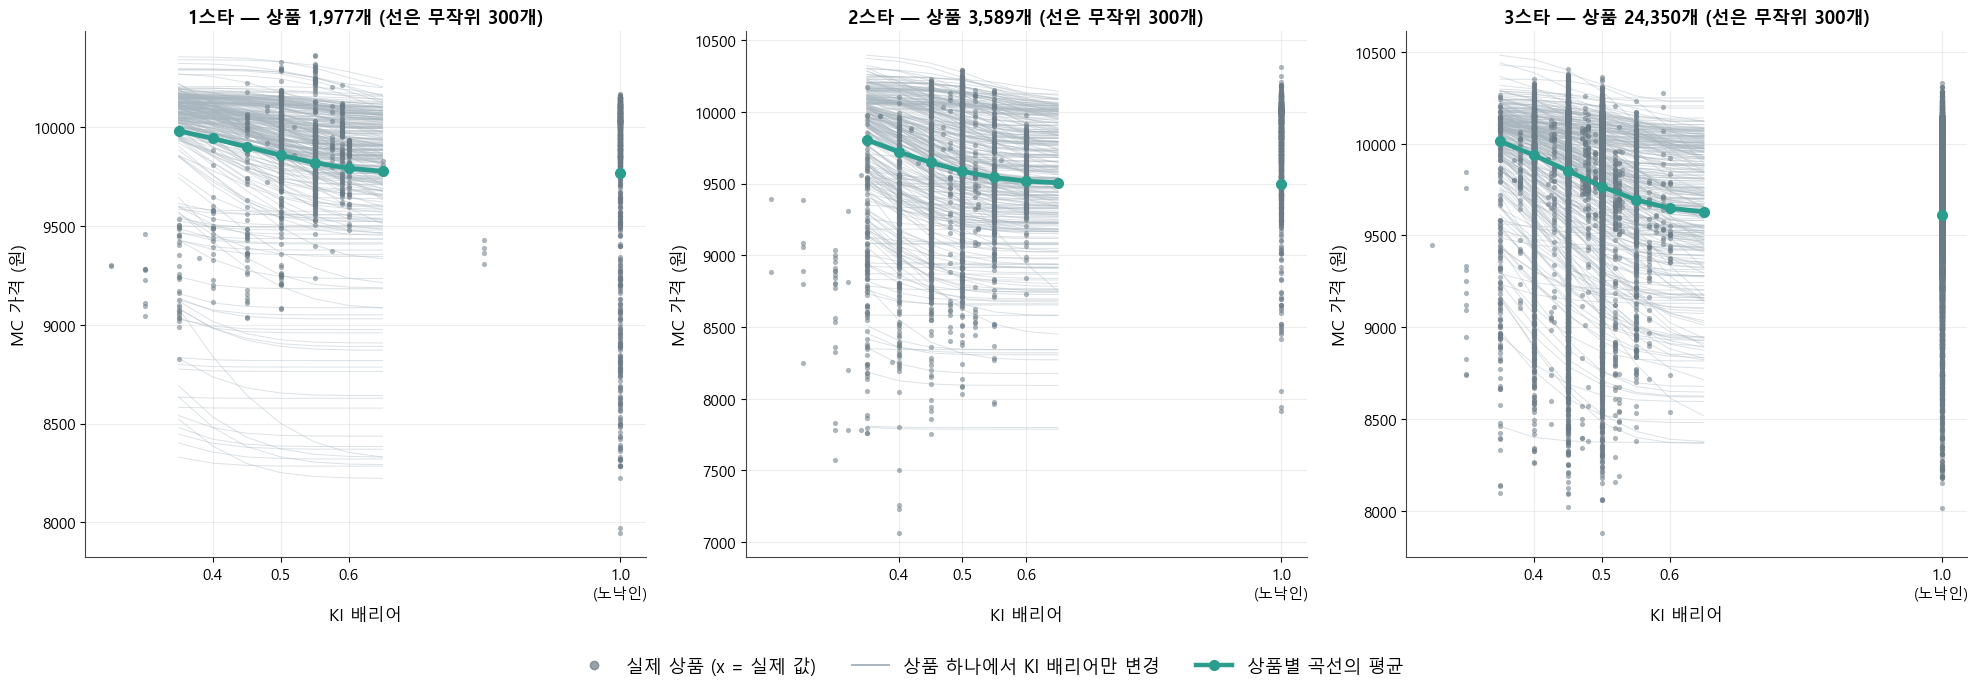

저장 result/image/fig_03_products_mc_barrier.png  + .csv
  계약조건  스타  상품 수  수준 수  실제 값이 수준 범위 안(%)  점−선 |차이| 중위(원)  평균선 처음→끝(원)
KI 배리어   1  1977     8              97.9             0.0       -211.7
KI 배리어   2  3589     8              95.8             0.0       -305.9
KI 배리어   3 24350     8              99.3             0.0       -404.0


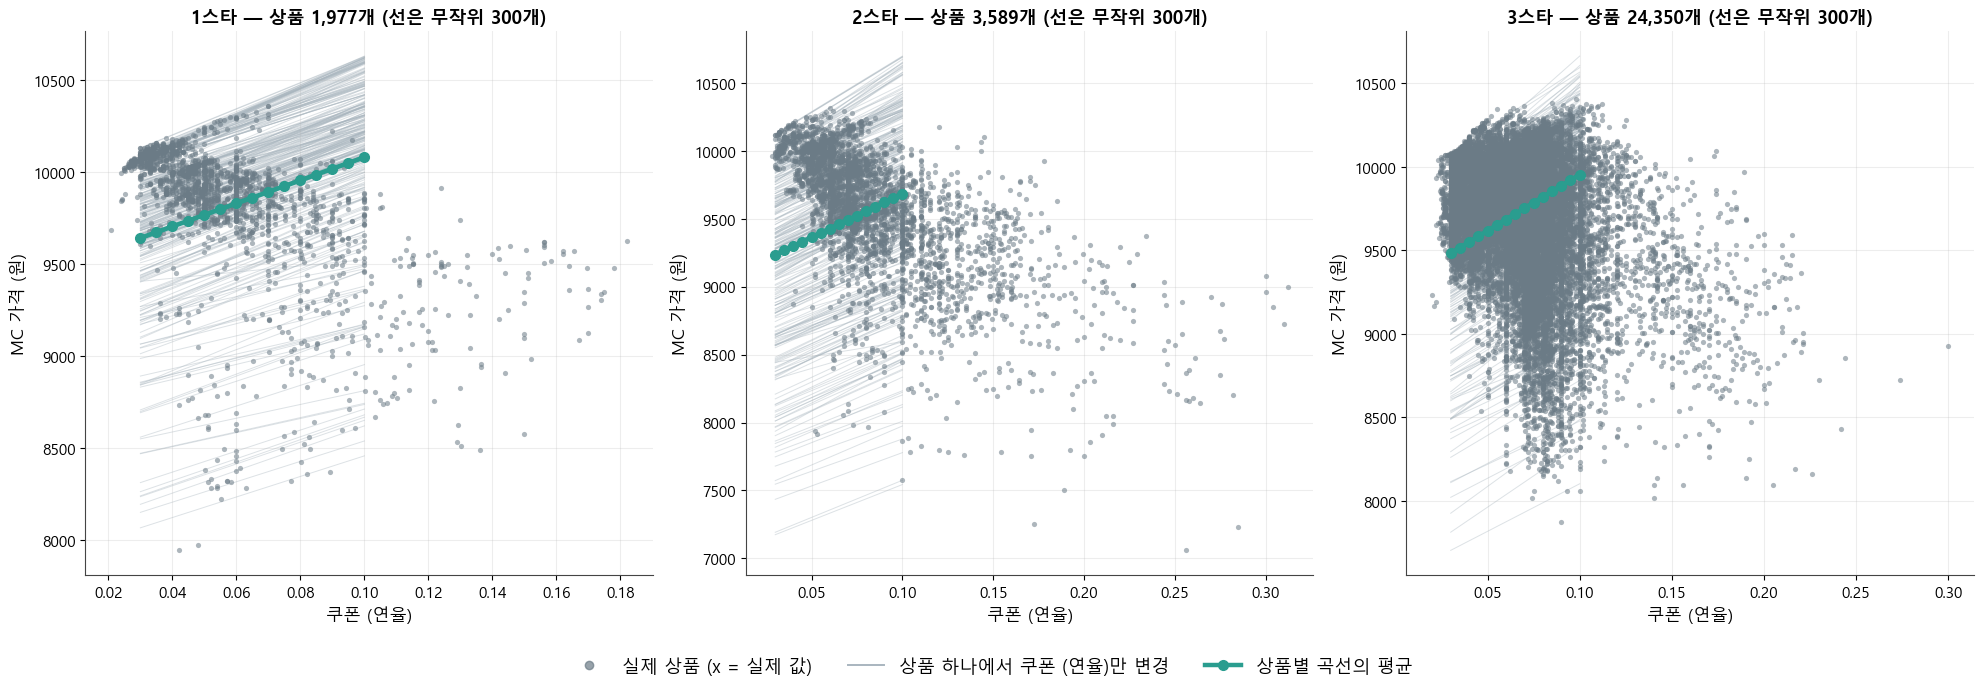

저장 result/image/fig_03_products_mc_coupon.png  + .csv
   계약조건  스타  상품 수  수준 수  실제 값이 수준 범위 안(%)  점−선 |차이| 중위(원)  평균선 처음→끝(원)
쿠폰 (연율)   1  1977    15              87.8             0.0        439.0
쿠폰 (연율)   2  3589    15              72.5             0.0        448.3
쿠폰 (연율)   3 24350    15              91.3             0.0        471.0


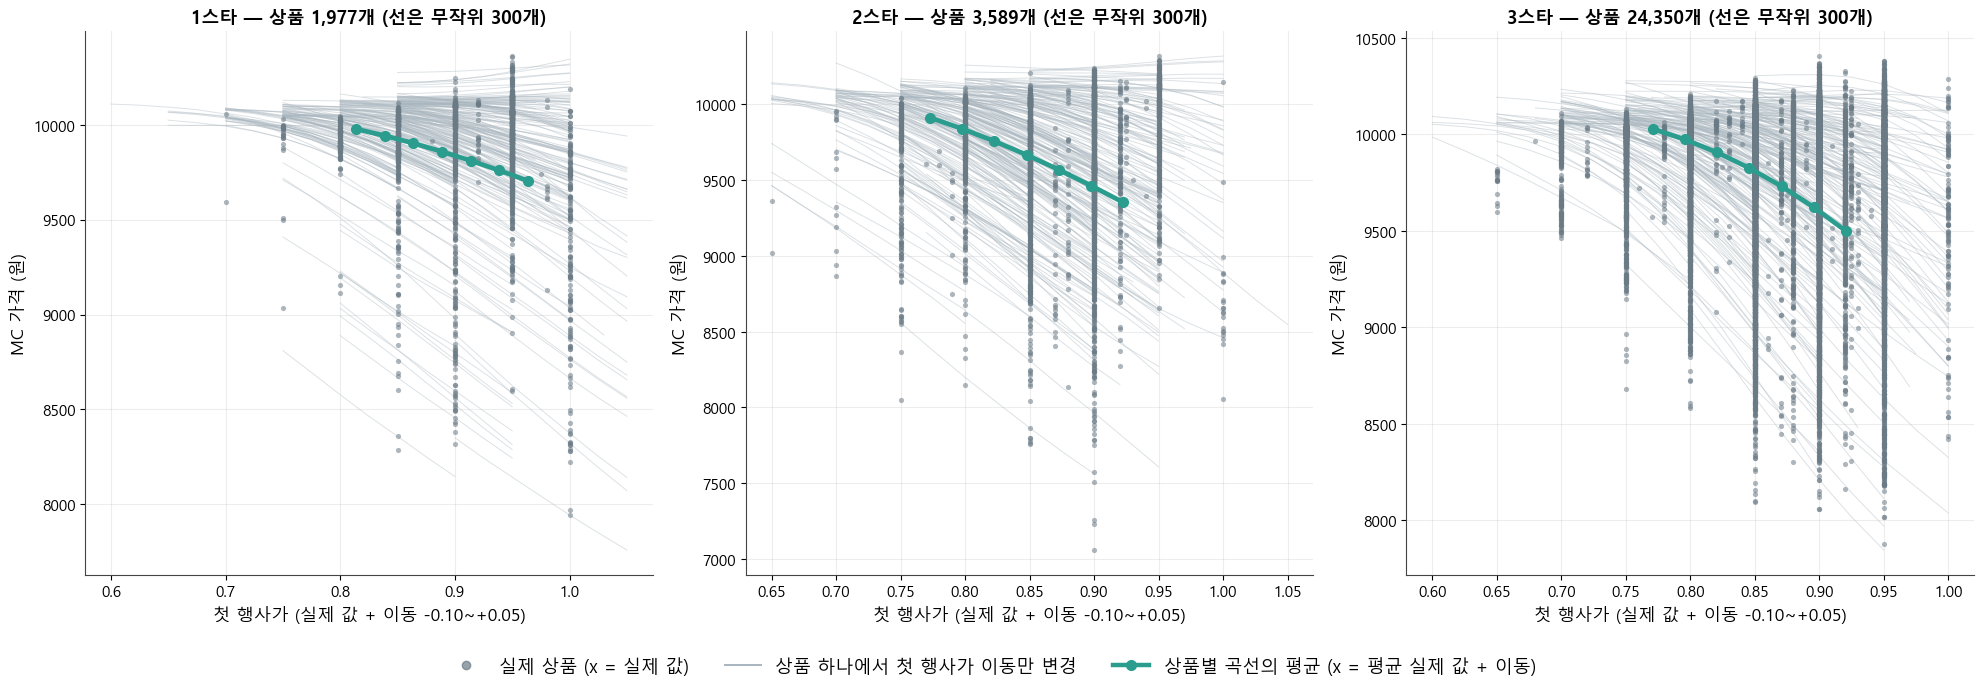

저장 result/image/fig_03_products_mc_strike_shift.png  + .csv
    계약조건  스타  상품 수  수준 수  실제 값이 수준 범위 안(%)  점−선 |차이| 중위(원)  평균선 처음→끝(원)
첫 행사가 이동   1  1977     7             100.0             0.0       -273.2
첫 행사가 이동   2  3589     7             100.0             0.0       -559.0
첫 행사가 이동   3 24350     7             100.0             0.0       -529.9


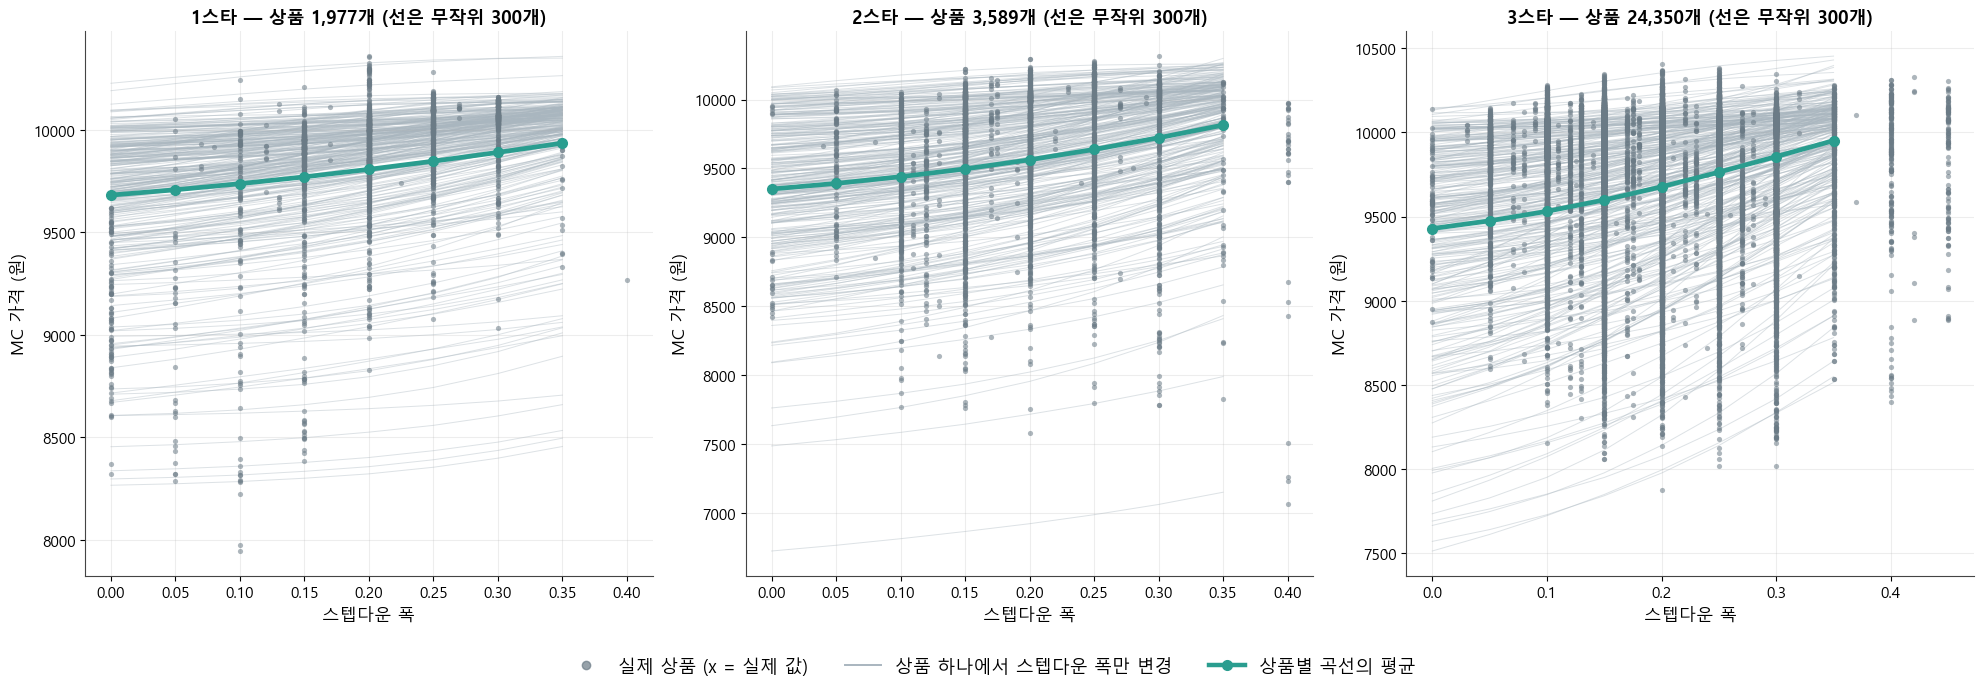

저장 result/image/fig_03_products_mc_spread.png  + .csv
  계약조건  스타  상품 수  수준 수  실제 값이 수준 범위 안(%)  점−선 |차이| 중위(원)  평균선 처음→끝(원)
스텝다운 폭   1  1977     8              99.8             0.0        253.6
스텝다운 폭   2  3589     8              98.6             0.0        464.3
스텝다운 폭   3 24350     8              98.0             0.0        523.0


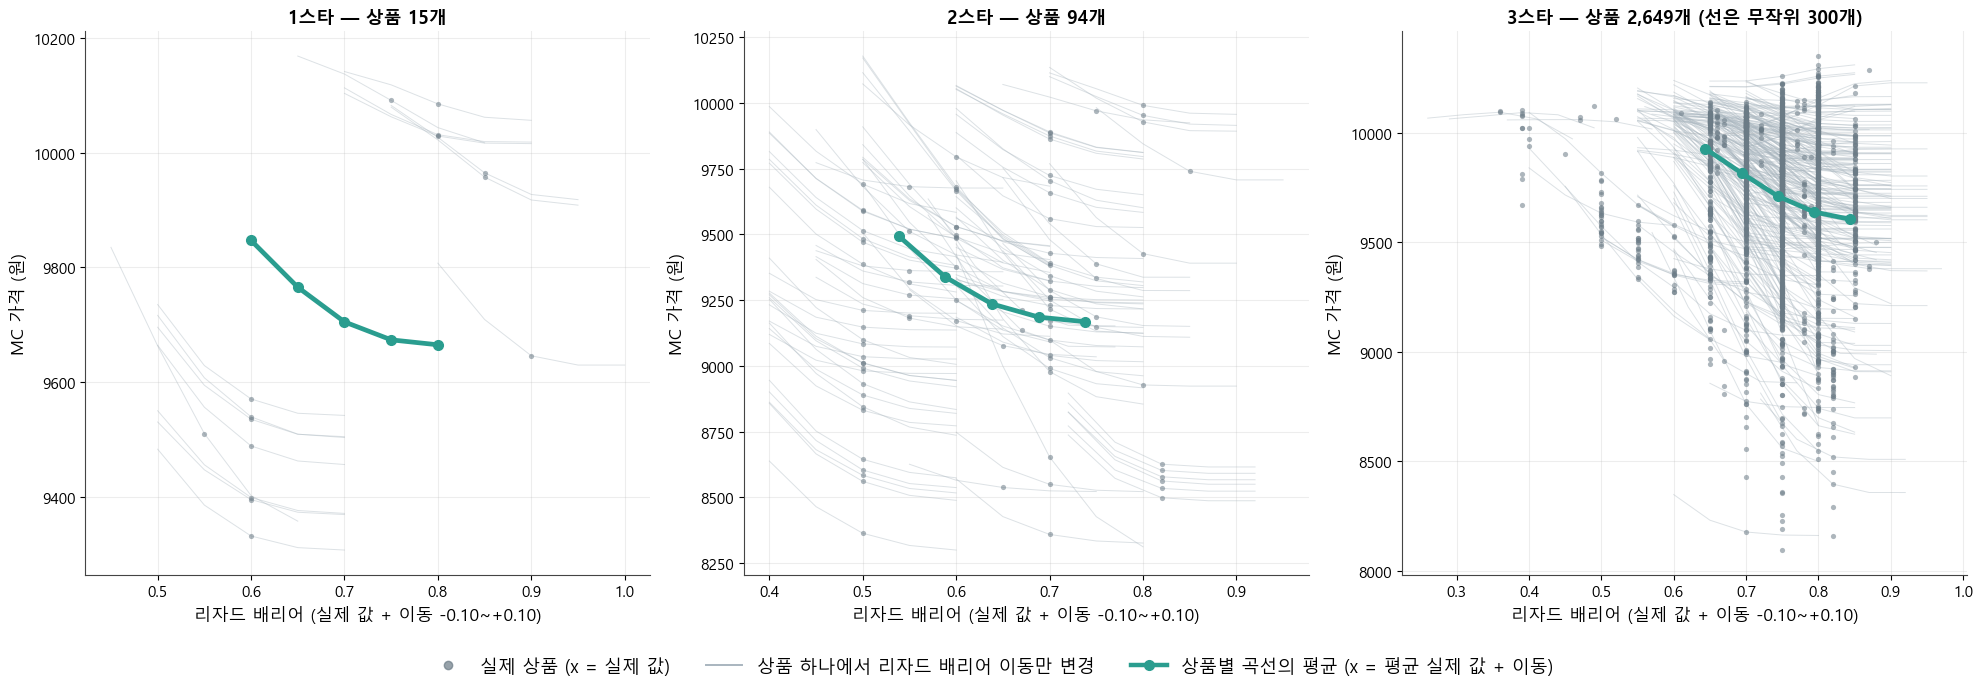

저장 result/image/fig_03_products_mc_lz_shift.png  + .csv
      계약조건  스타  상품 수  수준 수  실제 값이 수준 범위 안(%)  점−선 |차이| 중위(원)  평균선 처음→끝(원)
리자드 배리어 이동   1    15     5             100.0             0.0       -181.9
리자드 배리어 이동   2    94     5             100.0             0.0       -326.2
리자드 배리어 이동   3  2649     5             100.0             0.0       -322.0


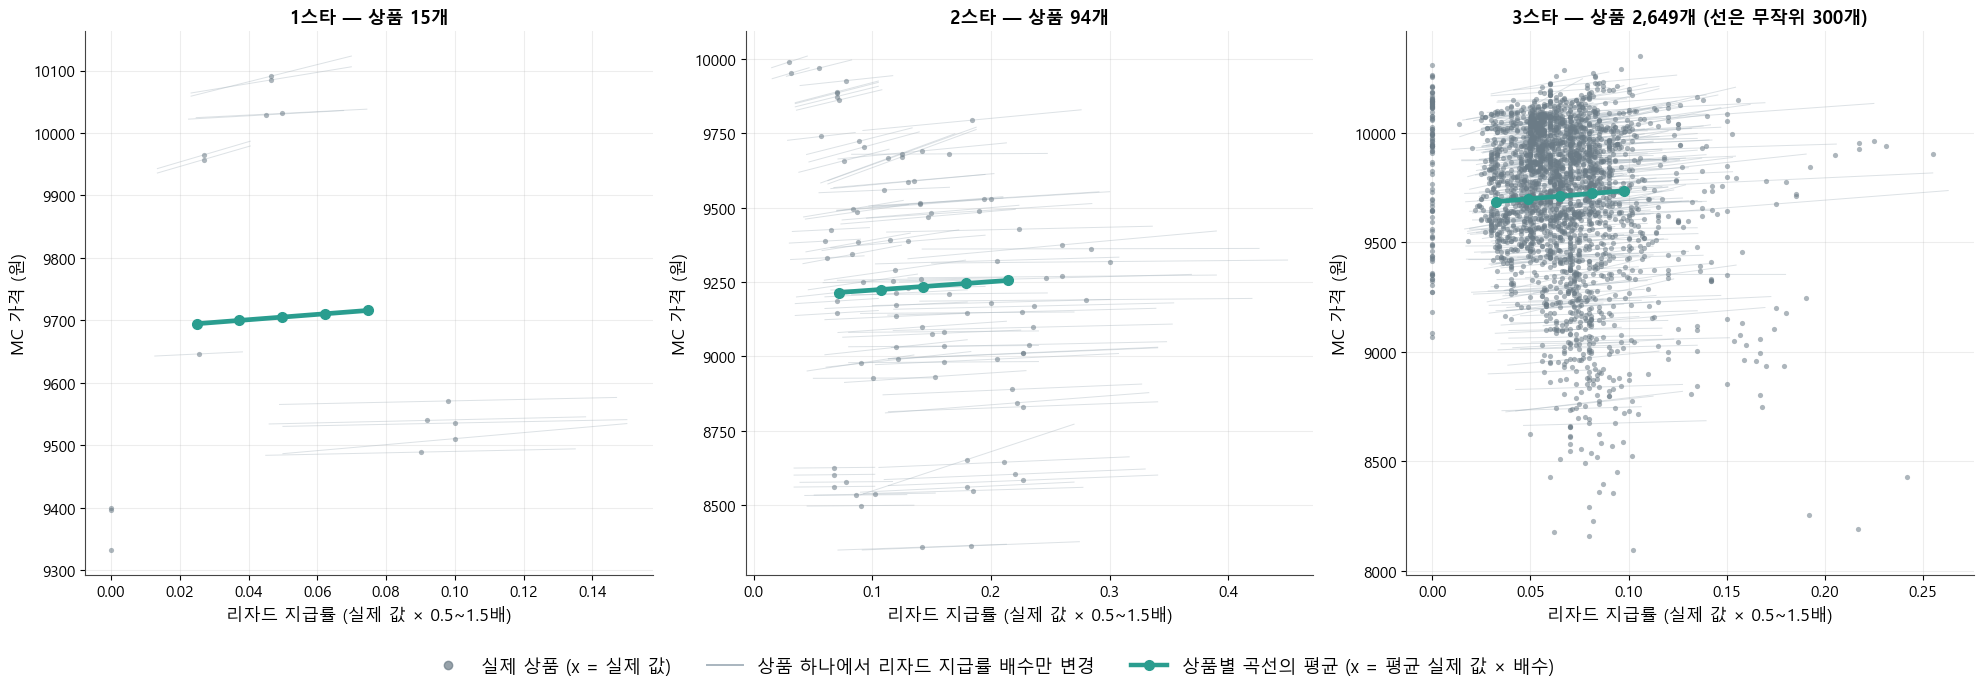

저장 result/image/fig_03_products_mc_lz_pmt_scale.png  + .csv
      계약조건  스타  상품 수  수준 수  실제 값이 수준 범위 안(%)  점−선 |차이| 중위(원)  평균선 처음→끝(원)
리자드 지급률 배수   1    15     5             100.0             0.0         21.3
리자드 지급률 배수   2    94     5             100.0             0.0         40.5
리자드 지급률 배수   3  2649     5             100.0             0.0         49.8


In [22]:
def fig_products_by_term() -> None:
    """계약조건마다 한 장 — fig_03_mono_effect_products_mc_top 과 같은 그림 (MC).

    회색 선 = 상품 하나에서 그 조건만 GRID 수준으로 변경, 회색 점 = 실제 상품
    (x = 그 상품의 실제 조건 값, 이동형 조건은 0 · y = 정본 MC), 초록 = 수준별 평균.
    점이 자기 선 위에 놓이는지(정본 MC 와 섭동 MC 가 같은 엔진인지)도 표로 남긴다.
    """
    from generate.eval_cross_section import build_terms
    from matplotlib.lines import Line2D
    B = bundle()
    D, mc = B["D"], B["mc"]
    T = build_terms(D)
    idx_of = {it: i for i, it in enumerate(D.ITEM)}
    M = mc_table()
    # x 축은 모두 실제 조건 값. 이동형은 (실제 값 + 이동), 배수형은 (실제 값 × 배수) 에 선을 긋는다
    actual = {"barrier": T["barrier"], "coupon": T["coupon"], "spread": T["spread"],
              "strike_shift": T["strike_shift"], "lz_shift": T["lz_shift"], "lz_pmt_scale": T["lz_pmt_scale"]}
    rel = {"strike_shift": "add", "lz_shift": "add", "lz_pmt_scale": "mul"}
    XL = {"barrier": "KI 배리어", "coupon": "쿠폰 (연율)", "spread": "스텝다운 폭",
          "strike_shift": "첫 행사가 (실제 값 + 이동 -0.10~+0.05)",
          "lz_shift": "리자드 배리어 (실제 값 + 이동 -0.10~+0.10)",
          "lz_pmt_scale": "리자드 지급률 (실제 값 × 0.5~1.5배)"}
    rng = np.random.default_rng(0)
    for f in ["barrier", "coupon", "strike_shift", "spread", "lz_shift", "lz_pmt_scale"]:
        Z = M[M["factor"] == f]
        stars = [s for s in (1, 2, 3) if Z[Z["nstar"] == s]["item"].nunique() > 0]
        if not stars:
            print("  {}: 섭동 MC 없음 — 건너뜀".format(f))
            continue
        fig, axes = plt.subplots(1, len(stars), figsize=(20.0, 7.0), squeeze=False)
        rows = []
        for ax, ns in zip(axes[0], stars):
            piv = Z[Z["nstar"] == ns].pivot_table(index="item", columns="level", values="mc").dropna()
            lv = piv.columns.to_numpy(float)
            Y = piv.to_numpy()
            ii = np.array([idx_of[it] for it in piv.index])
            xa, ya = actual[f][ii], mc[ii]
            show = np.arange(len(ii)) if len(ii) <= 300 else rng.choice(len(ii), 300, replace=False)
            if f in rel:  # 상품마다 자기 실제 값 주변에 선 — x 행렬 (상품 × 수준)
                XX = xa[:, None] + lv[None, :] if rel[f] == "add" else xa[:, None] * lv[None, :]
                xm = xa.mean() + lv if rel[f] == "add" else xa.mean() * lv
                l0 = 0.0 if rel[f] == "add" else 1.0
                gap = Y[:, list(np.round(lv, 4)).index(l0)] - ya
                on = np.ones(len(ii), bool)
            else:
                XX, xm = np.broadcast_to(lv, Y.shape), lv
                on = (xa >= lv.min()) & (xa <= lv.max())
                gap = np.array([np.interp(x, lv, y) for x, y in zip(xa[on], Y[on])]) - ya[on]
            for k in show:
                lplot(ax, f, XX[k], Y[k], "-", color="#a9b6bf", lw=0.7, alpha=0.4, zorder=1, marker="")
            ax.scatter(xa, ya, s=14, color="#6b7b86", alpha=0.55, lw=0, zorder=3)
            lplot(ax, f, xm, Y.mean(0), "-", marker="o", color="#2a9d8f", lw=3.4, ms=7, zorder=6)
            rows.append({"계약조건": TITLE[f], "스타": ns, "상품 수": len(ii), "수준 수": len(lv),
                         "실제 값이 수준 범위 안(%)": float(on.mean() * 100),
                         "점−선 |차이| 중위(원)": float(np.median(np.abs(gap))) if on.any() else np.nan,
                         "평균선 처음→끝(원)": float(Y.mean(0)[-1] - Y.mean(0)[0])})
            note = "" if len(show) == len(ii) else " (선은 무작위 {}개)".format(len(show))
            ax.set_title("{}스타 — 상품 {:,}개{}".format(ns, len(ii), note), fontweight="bold", fontsize=13)
            ax.set_xlabel(XL[f], fontsize=12.5)
            ax.set_ylabel("MC 가격 (원)", fontsize=12.5)
            ax.grid(alpha=0.22)
        lab2 = "상품별 곡선의 평균" if f not in rel else \
            "상품별 곡선의 평균 (x = 평균 실제 값 {})".format("+ 이동" if rel[f] == "add" else "× 배수")
        handles = [Line2D([0], [0], color="#6b7b86", lw=0, marker="o", ms=6, alpha=0.7, label="실제 상품 (x = 실제 값)"),
                   Line2D([0], [0], color="#a9b6bf", lw=1.4, label="상품 하나에서 {}만 변경".format(TITLE[f])),
                   Line2D([0], [0], color="#2a9d8f", lw=3.2, marker="o", ms=7, label=lab2)]
        fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=13)
        fig.tight_layout(rect=[0, 0.07, 1, 1])
        save(fig, "fig_03_products_mc_{}".format(f), pd.DataFrame(rows))
        print(pd.DataFrame(rows).round(1).to_string(index=False))


fig_products_by_term()